HankelDMD is a variant of DMD introduced in the paper "Ergodic theory, Dynamic Mode Decomposition and
Computation of Spectral Properties of the Koopman operator" (https://arxiv.org/pdf/1611.06664.pdf). In its simplest form, one converts their data matrix into a pseudo-Hankel matrix, and then fits exact DMD to this.

A Hankel matrix is a square matrix in which skew-diagonals from left to right are constant. Thus, the Hankel matrix associated with the time series of a single feature $x_1,\ldots,x_{2n}$ is the following $n\times n$ matrix:
$$\begin{bmatrix} 
    x_1 & x_2 & x_3 & \ldots & x_n \\
    x_2 & x_3 & x_4 & \ldots & x_{n+1} \\
    x_3 & x_4 & x_5 & \ldots & x_{n+2} \\
    \vdots & \ddots & \ddots & \ddots & \vdots \\
    x_n & x_{n+1} & x_{n+2} & \ldots & x_{2n}
  \end{bmatrix}.$$
  
DMD takes this Hankel matrix to the following one:

$$\begin{bmatrix} 
    x_2 & x_3 & x_4 & \ldots & x_{n+1} \\
    x_3 & x_4 & x_5 & \ldots & x_{n+2} \\
    x_4 & x_5 & x_6 & \ldots & x_{n+3} \\
    \vdots & \ddots & \ddots & \ddots & \vdots \\
    x_{n+1} & x_{n+2} & x_{n+3} & \ldots & x_{2n+1}
  \end{bmatrix}.$$

When we have multiple, say $k$, features, we just form Hankel matrices for each of them, stack them on top of each other one by one, and fit exact DMD to each.

To compute the reconstruction of our original data from the reconstruction of its Hankel matrix, we average across the skew-diagonals. For example, if the first matrix above was our Hankel matrix reconstruction, we would average the three entries corresponding to $x_3$, and this would be our prediction for $x_3$ in the data.

All that being said, with HankelDMD we do not form a true Hankel matrix, but rather a pseudo-Hankel matrix of the form
$$\begin{bmatrix} x_1 & x_2 & x_3 & \ldots & x_{n-d+1} \\
                  x_2 & x_3 & x_4 & \ldots & x_{n-d+2} \\
                  x_3 & x_4 & x_5 & \ldots & x_{n-d+3} \\
                  \vdots & \ddots & \ddots & \ddots & \vdots \\
                  x_d & x_{d+1} & x_{d+2} & \ldots & x_{n}
  \end{bmatrix}.$$
  
Here $d$ is a hyperparameter that determines how much time-delay embedding we want to do. When $d=1$, HankelDMD reduces to ExactDMD and we underfit our data. I have noticed that as $d\to n$, we overfit our data.

HankelDMD has many pros and cons. The pros are that it appears to work extremely well, and there are strong theoretical guarantees for it in the paper above for ergodic systems. Namely, the eigenvalues of the DMD operator it constructs are guaranteed to converge to the Koopman eigenvalues as $n\to\infty$, and the projections of the eigenvectors onto the basis of left singular vectors of the data (what one gets with hankeldmd.modes) are guaranteed to converge to the Koopman eigenfunctions. The cons are that HankelDMD decomposes the Hankel matrix version of our data into modes and complex exponentials rather than the data itself. Hence it's not clear to me yet how to interpret the modes that HankelDMD finds.

We will start out by fitting with a very large value of $d$ relative to the number of timepoints $n$.

In [1]:
import numpy as np
from pydmd import HankelDMD, DMD
from BopDMD_Regularized import BOPDMD
from MrOptDMD import MrOptDMD
from pydmd.utils import compute_svd
import matplotlib.pylab as plt
from tqdm.auto import tqdm
plt.rcParams['figure.dpi']=400
np.set_printoptions(suppress=True,precision=6,linewidth=100000) # Improve print statements

RSE = lambda X,Y: np.sum((Y-np.real(X))**2)/np.sum((Y-np.mean(Y))**2)
# Model reconstruction = X, true data = Y

SV = np.load('../Mouse Data/svdTemporalComponents_corr.npy')[:2000,:50].T
SV_norm = np.linalg.norm(SV)
SV_normalized = SV / SV_norm

dmd = DMD(24)
hdmd = HankelDMD(24,reconstruction_method='mean',d=950)
optdmd = BOPDMD(24)
mroptdmd = MrOptDMD([BOPDMD(10),BOPDMD(6),BOPDMD(8)],max_level=2,max_cycles=np.inf)

dmd.fit(SV_normalized[:,:1000])
hdmd.fit(SV_normalized[:,:1000])
mroptdmd.fit(SV_normalized[:,:1000],np.arange(1000))
optdmd.fit(SV_normalized[:,:1000],np.arange(1000))

print("DMD RSE: " + str(RSE(dmd.reconstructed_data,SV_normalized[:,:1000])))
print("Hankel DMD RSE: " + str(RSE(hdmd.reconstructed_data,SV_normalized[:,:1000])))
print("MrOptDMD RSE: " + str(RSE(mroptdmd.reconstructed_data,SV_normalized[:,:1000])))
print("OptDMD RSE: " + str(RSE(optdmd.reconstructed_data,SV_normalized[:,:1000])))

DMD RSE: 0.6656806061290524
Hankel DMD RSE: 0.00030858957293432743
MrOptDMD RSE: 0.03020217212270541
OptDMD RSE: 0.0433885430542064


So HankelDMD achieves an accuracy about 100x greater than even MrOptDMD. To me, this is an indication of overfitting since it seems likely that more than 0.03% of the data is noise. Let's look at the eigenvalues predicted by these different models.

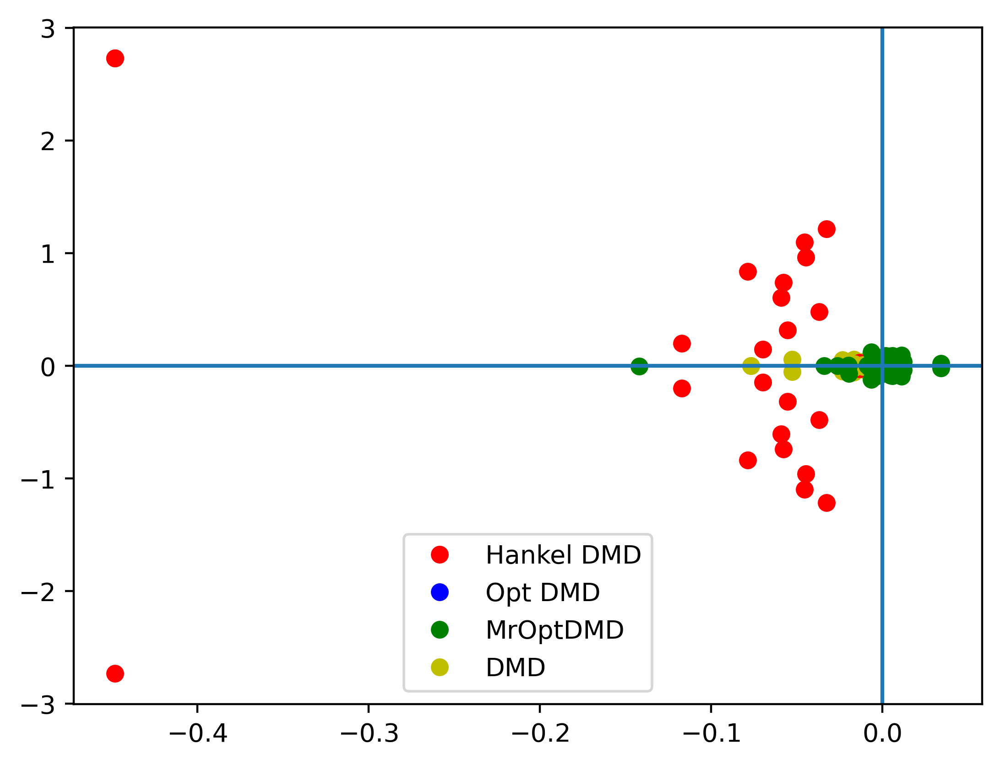

In [72]:
# Comparison of eigenvalues of Hankel DMD to eigenvalues of OptDMD/MrOptDMD
plt.plot(np.real(np.log(hdmd.eigs)[0]),np.imag(np.log(hdmd.eigs)[0]),'ro',label="Hankel DMD")
plt.plot(np.real(optdmd.eigs[0]),np.imag(optdmd.eigs[0]),'bo',label="Opt DMD")
plt.plot(np.real(mroptdmd.eigs[0]),np.imag(mroptdmd.eigs[0]),'go',label="MrOptDMD")
plt.plot(np.real(np.log(dmd.eigs)[0]),np.imag(np.log(dmd.eigs)[0]),'yo',label="DMD")
for heig, oeig, deig in zip(np.log(hdmd.eigs), optdmd.eigs,np.log(dmd.eigs)):
    plt.plot(np.real(heig),np.imag(heig),'ro')
    plt.plot(np.real(oeig),np.imag(oeig),'bo')
    plt.plot(np.real(deig),np.imag(deig),'yo')
for mreig in mroptdmd.eigs:
    plt.plot(np.real(mreig),np.imag(mreig),'go')
plt.axhline(0)
plt.axvline(0)
plt.legend()

So we can see that HankelDMD makes very different predictions than the other models. Some of these modes must correspond to noise because the frequencies predicted by HankelDMD go up to 17Hz, while the frequencies actually present in the data go up to about 5Hz.

Next we can look at the modes computed by HankelDMD, which are approximations of the Koopman eigenfunctions.

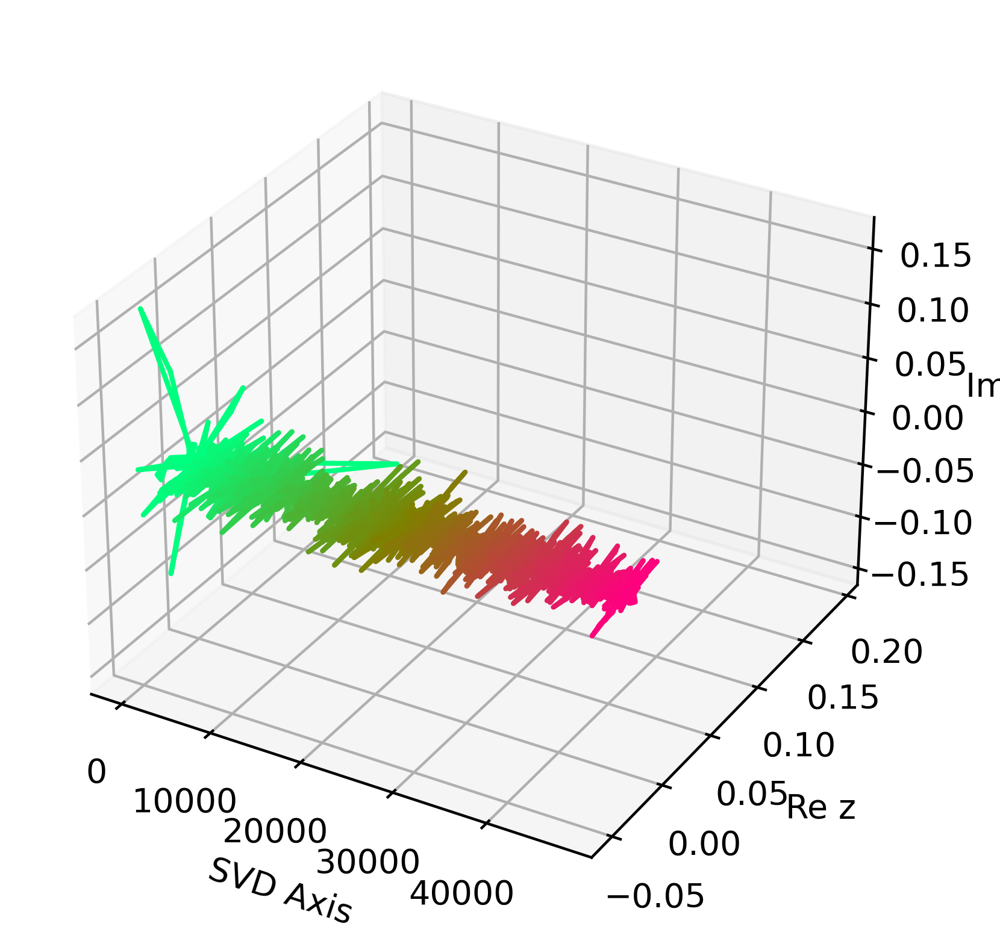

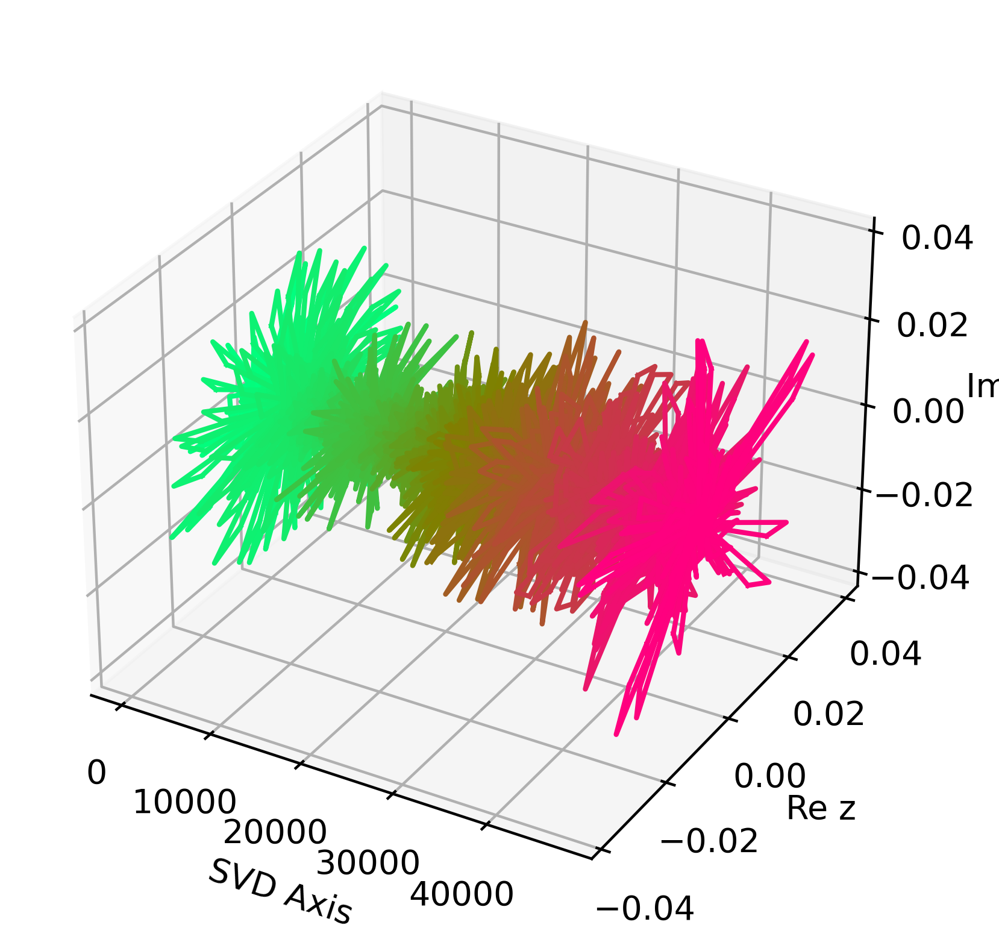

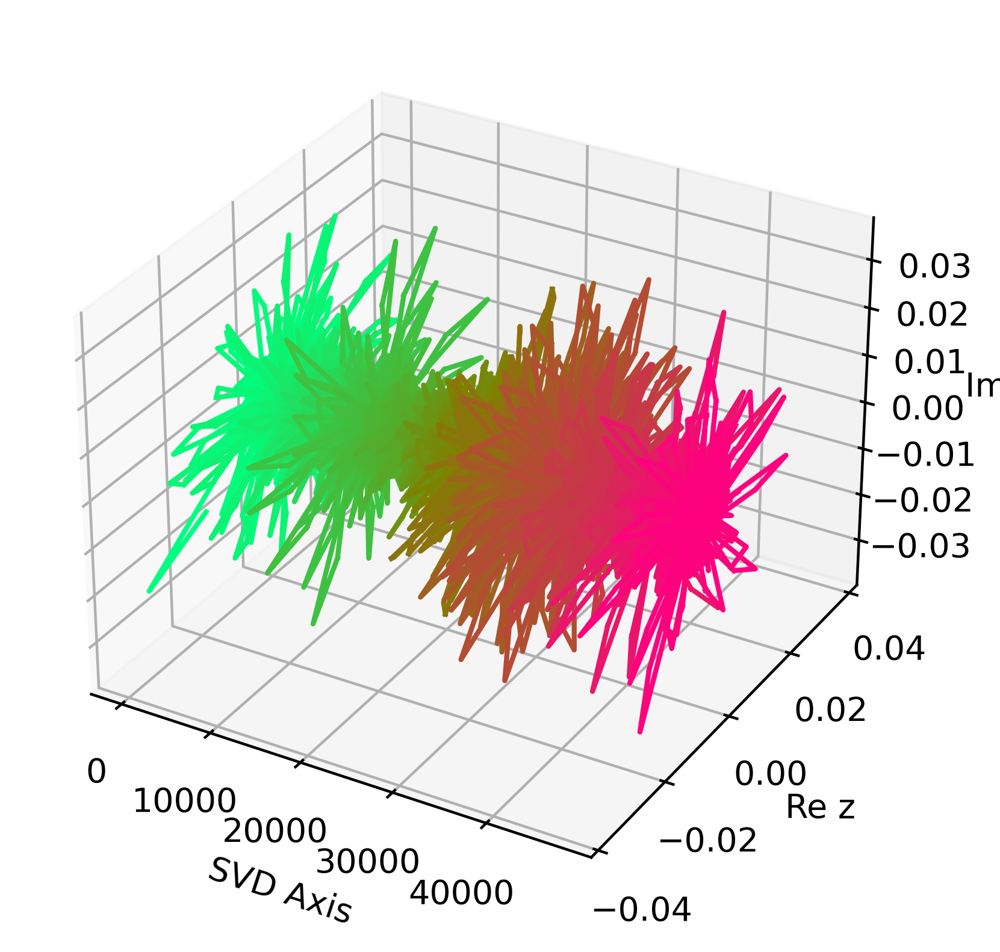

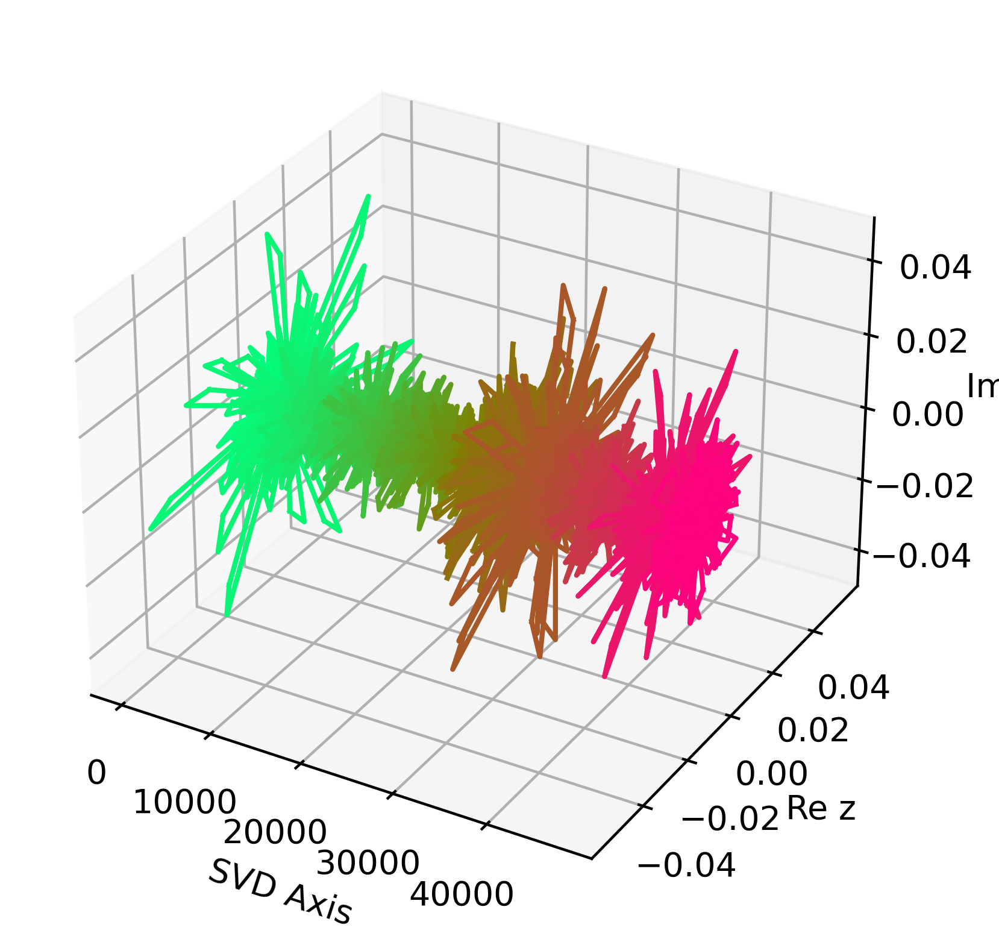

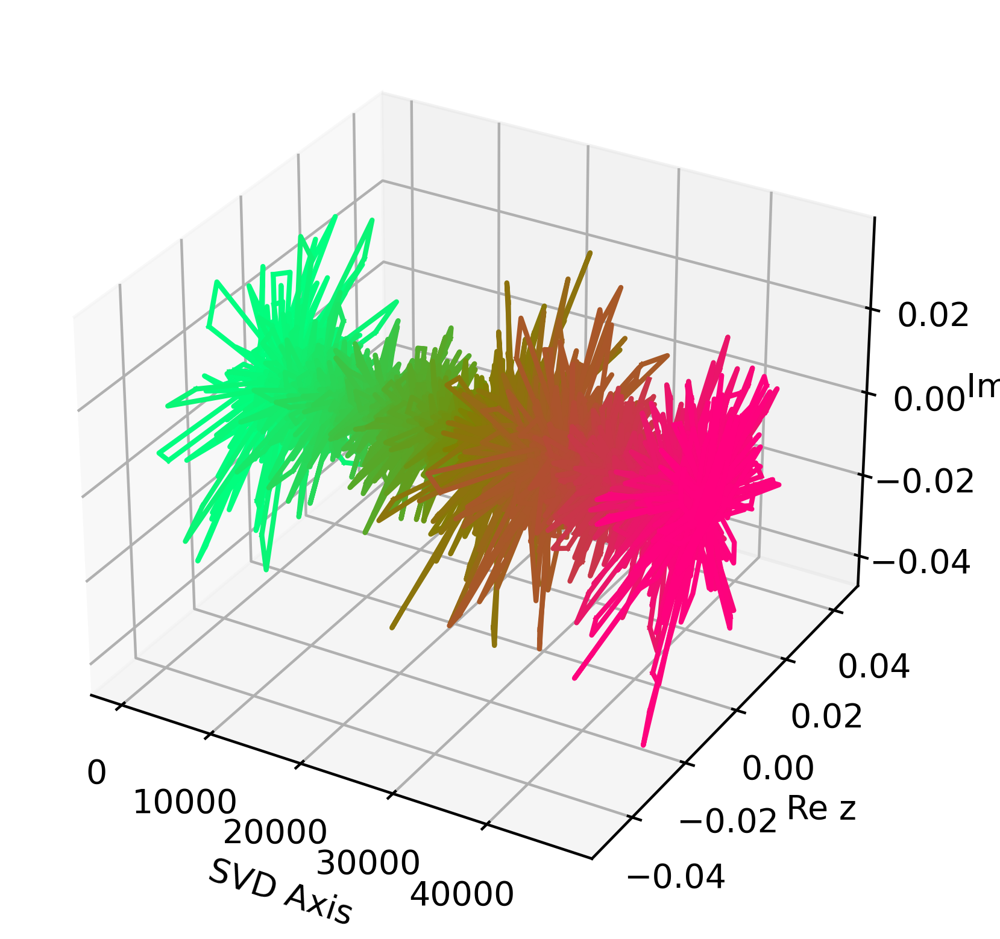

...

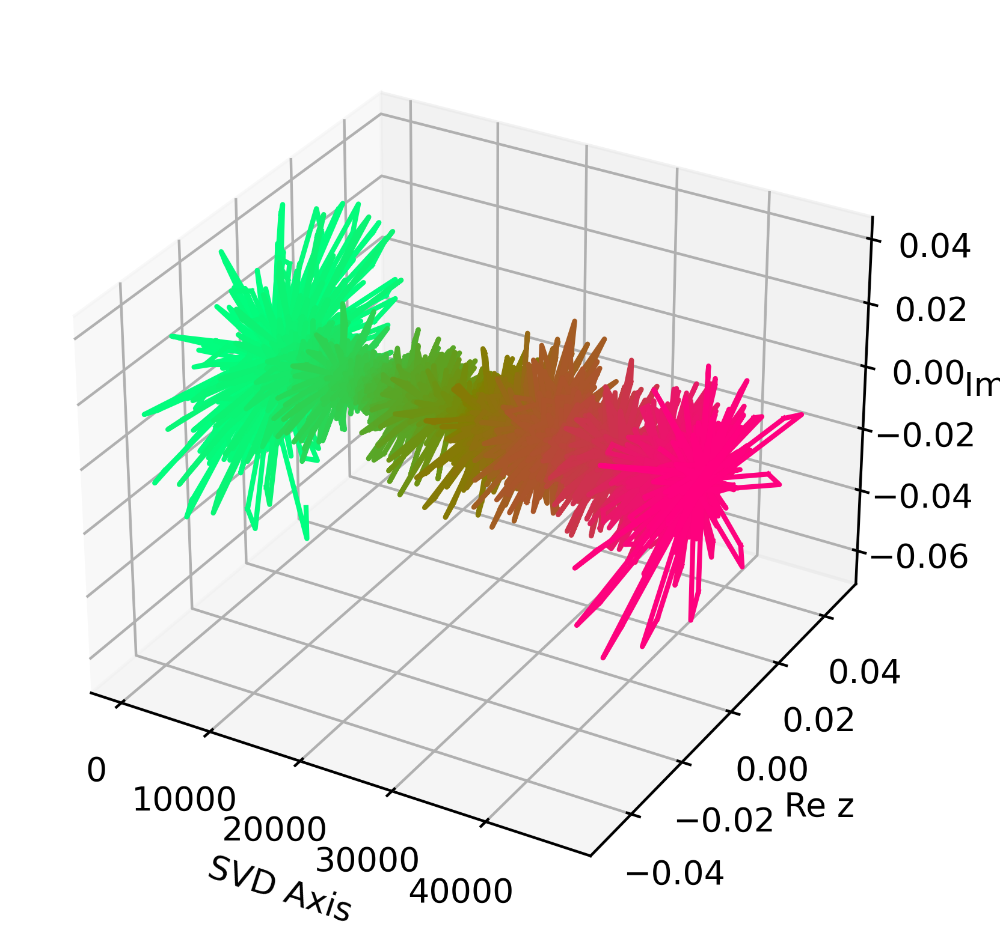

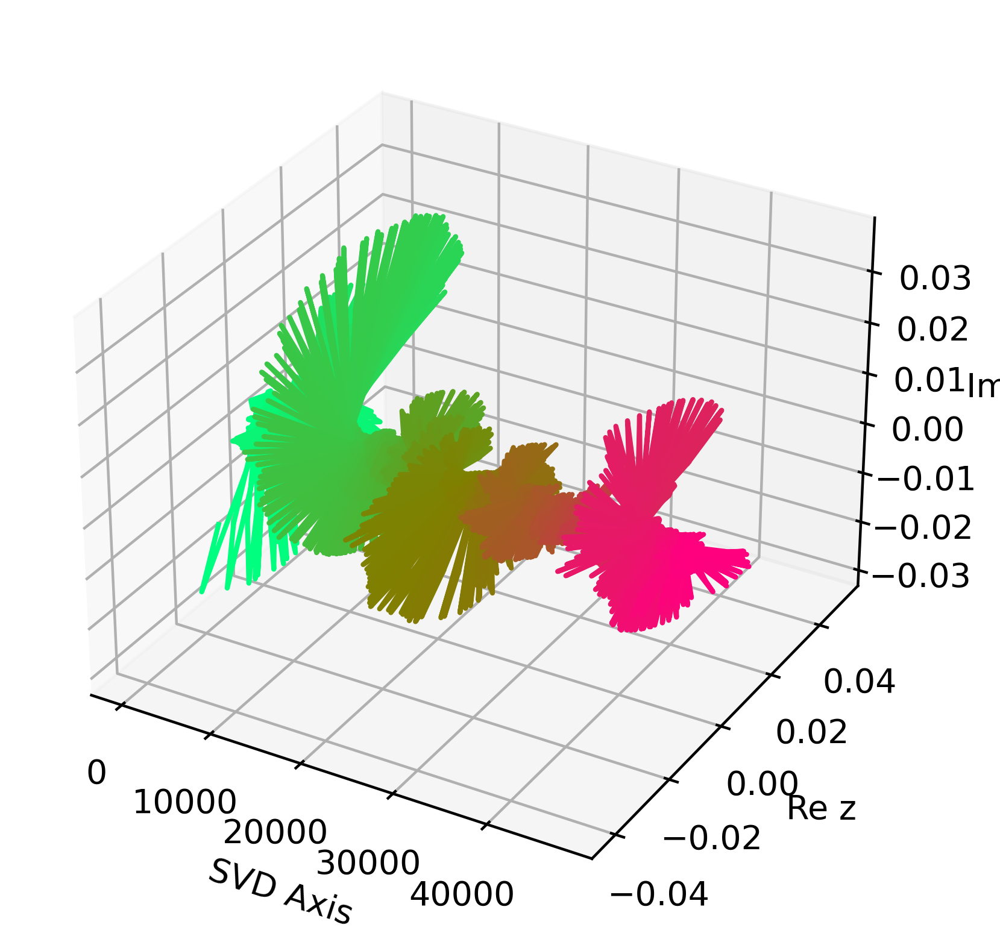

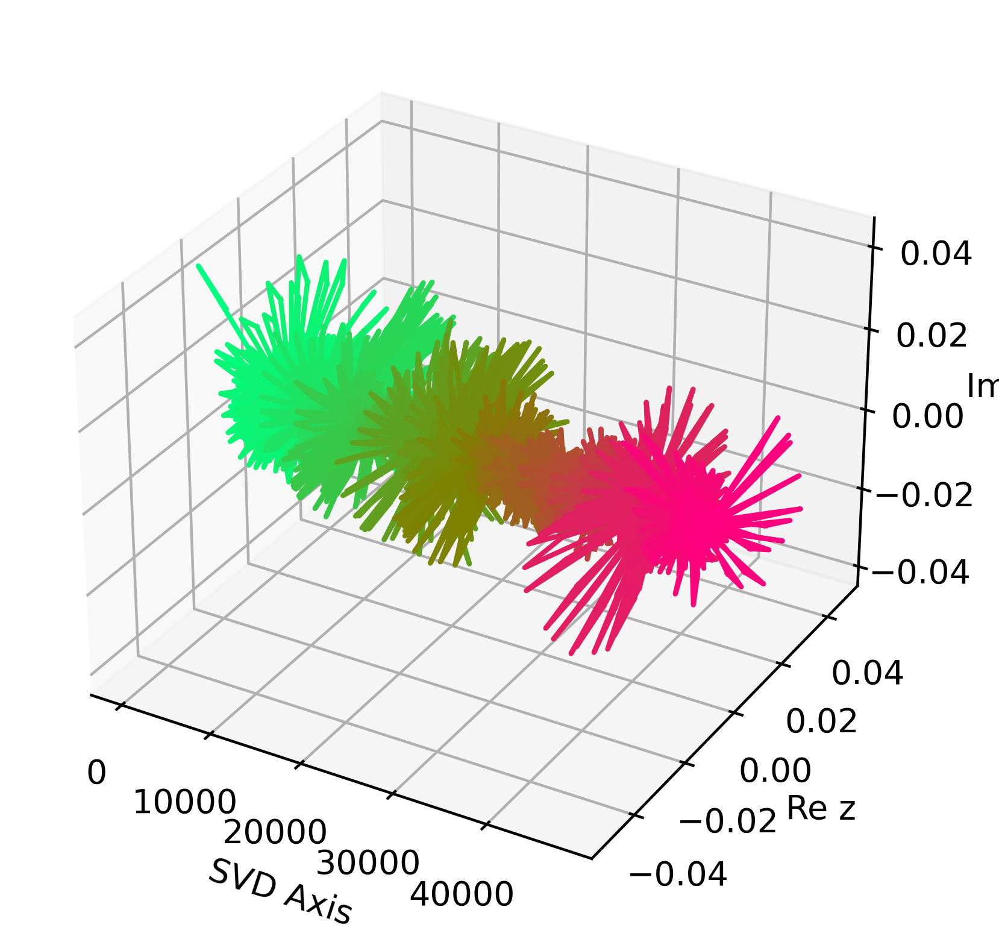

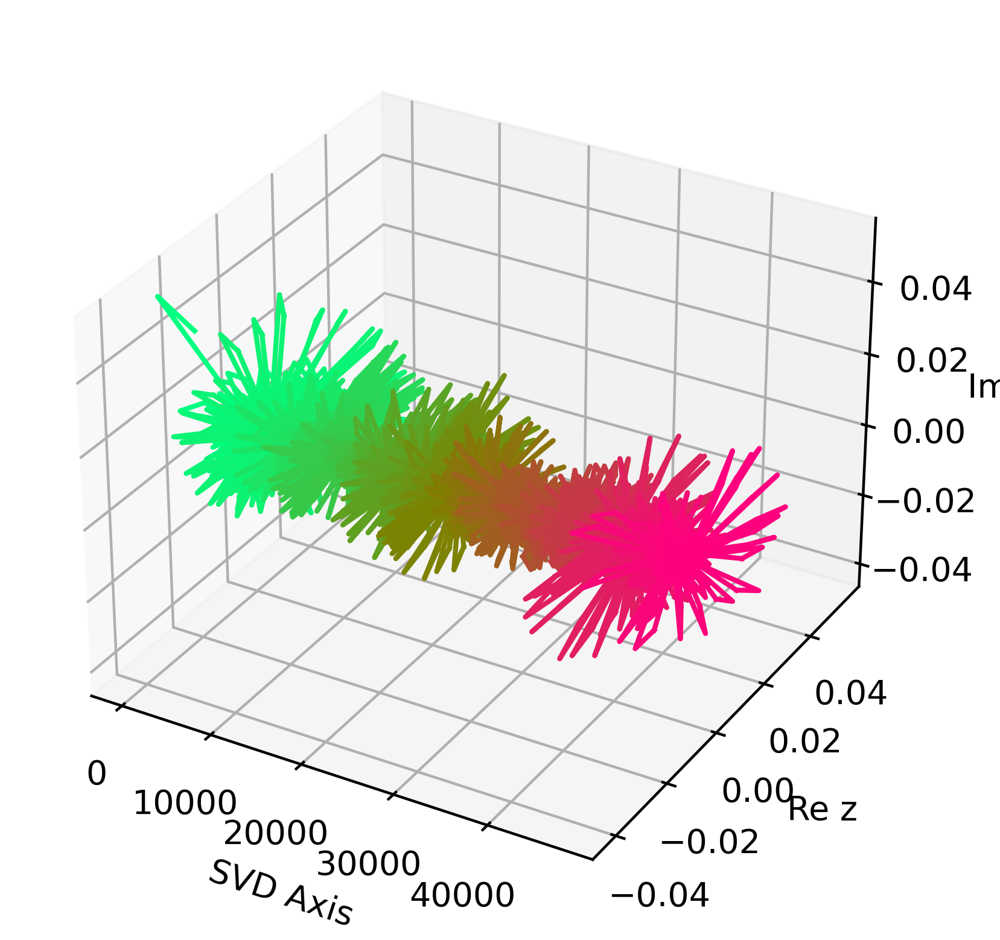

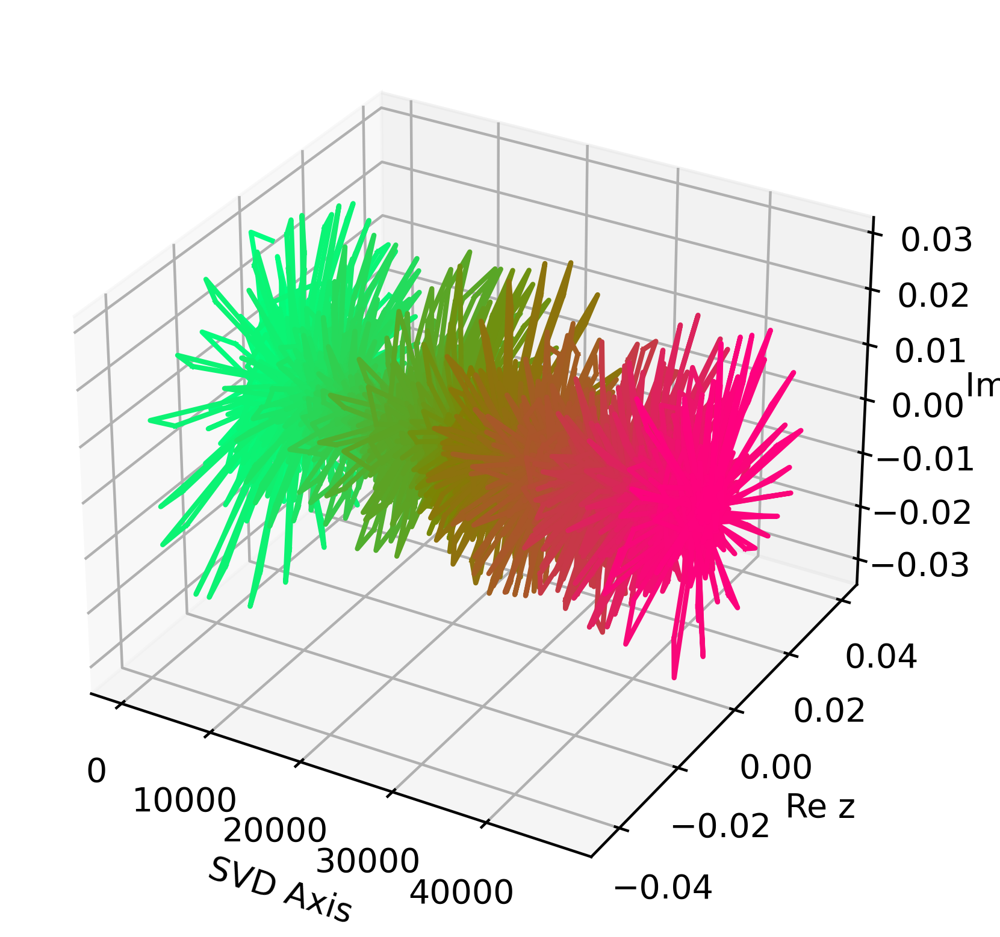

<Figure size 2560x1920 with 0 Axes>

In [74]:
n = 47500
for j in range(12):
    ax = plt.axes(projection='3d')
    for i in range(0, n, 50):
        r = i/n
        b = np.abs(n//2-i)/n
        g = (n-i)/n
        color = (r, g, b)
        ax.plot3D(np.arange(n)[i:i+51], np.real(hdmd.modes[:,2*j])[i:i+51], np.imag(hdmd.modes[:,2*j])[i:i+51],c=color)
    ax.set_xlabel("SVD Axis")
    ax.set_ylabel("Re z")
    ax.set_zlabel("Im z")
    plt.figure()

Now let's try again with a value of $d$ that gives a reconstruction RSE comparable to MrOptDMD and OptDMD.

In [327]:
hdmd = HankelDMD(24,reconstruction_method='mean',d=500)
hdmd.fit(SV_normalized[:,:1000])
print("Hankel DMD RSE: " + str(RSE(hdmd.reconstructed_data,SV_normalized[:,:1000])))
print("MrOptDMD RSE: " + str(RSE(mroptdmd.reconstructed_data,SV_normalized[:,:1000])))
print("OptDMD RSE: " + str(RSE(optdmd.reconstructed_data,SV_normalized[:,:1000])))

Hankel DMD RSE: 0.02279379783681871
MrOptDMD RSE: 0.03020217212270541
OptDMD RSE: 0.0433885430542064


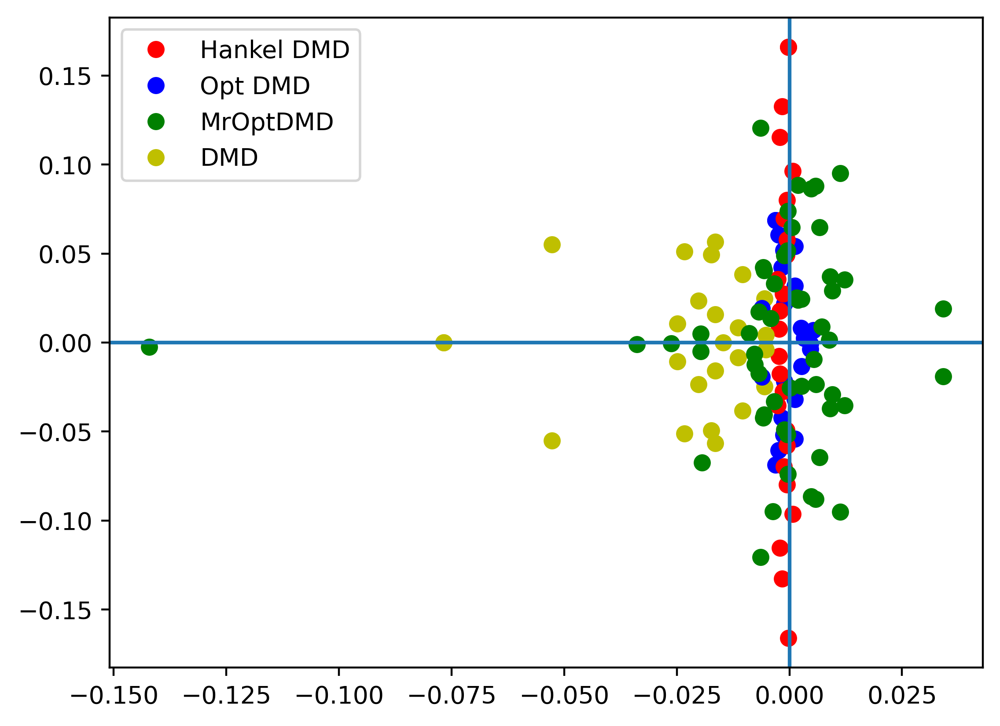

In [328]:
# Comparison of eigenvalues of Hankel DMD to eigenvalues of OptDMD/MrOptDMD
plt.plot(np.real(np.log(hdmd.eigs)[0]),np.imag(np.log(hdmd.eigs)[0]),'ro',label="Hankel DMD")
plt.plot(np.real(optdmd.eigs[0]),np.imag(optdmd.eigs[0]),'bo',label="Opt DMD")
plt.plot(np.real(mroptdmd.eigs[0]),np.imag(mroptdmd.eigs[0]),'go',label="MrOptDMD")
plt.plot(np.real(np.log(dmd.eigs)[0]),np.imag(np.log(dmd.eigs)[0]),'yo',label="DMD")
for heig, oeig, deig in zip(np.log(hdmd.eigs), optdmd.eigs,np.log(dmd.eigs)):
    plt.plot(np.real(heig),np.imag(heig),'ro')
    plt.plot(np.real(oeig),np.imag(oeig),'bo')
    plt.plot(np.real(deig),np.imag(deig),'yo')
for mreig in mroptdmd.eigs:
    plt.plot(np.real(mreig),np.imag(mreig),'go')
plt.axhline(0)
plt.axvline(0)
plt.legend();

With $d=500$, the accuracy seems more believable and the eigenvalues are not far from those predicted by OptDMD and MrOptDMD. Interestingly, it seems like HankelDMD makes more stable predictions than the OptDMD/MrOptDMD methods.

The modes look less noisy in this case. I don't know how to interpret them, but I do know that the modes are each of length 25000, corresponding to 500 timepoints (from $n-d=500$) times 50 PCA modes. I have plotted the modes with every 500 timepoints a different color, and it does seem like the fan/spiral structures correspond to the different modes.

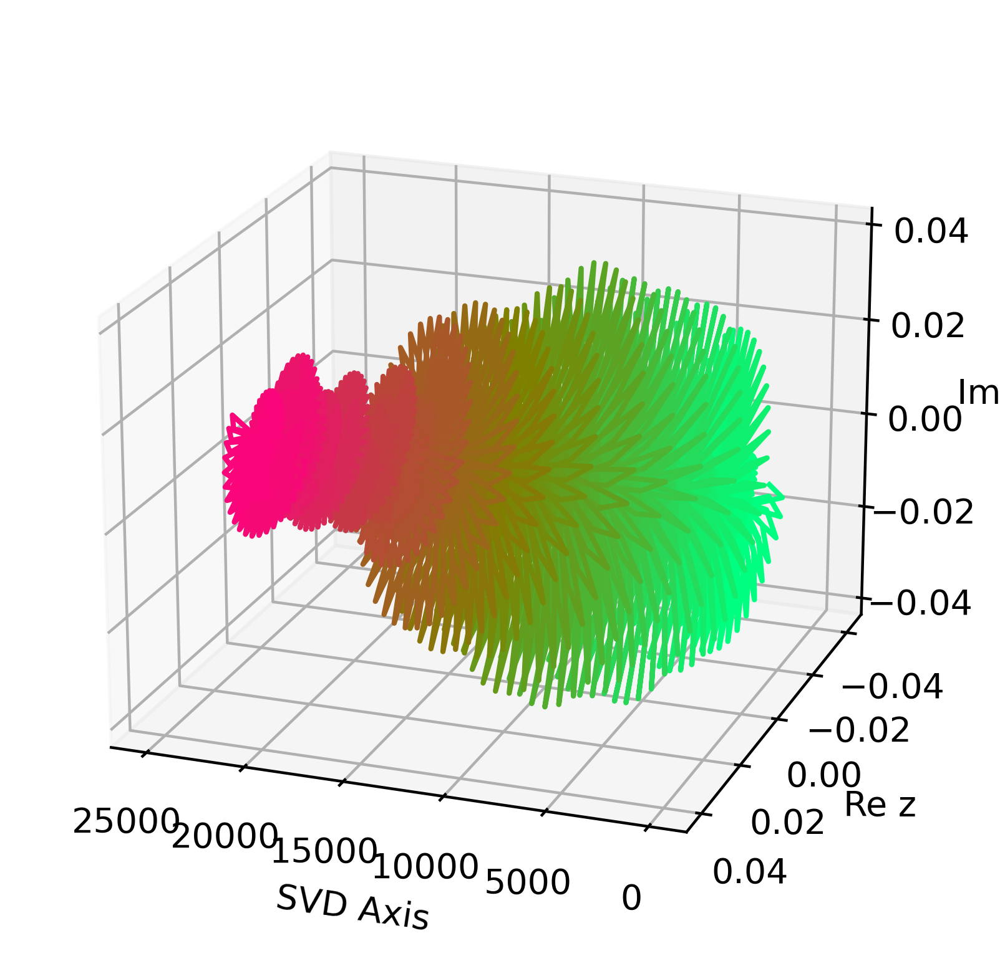

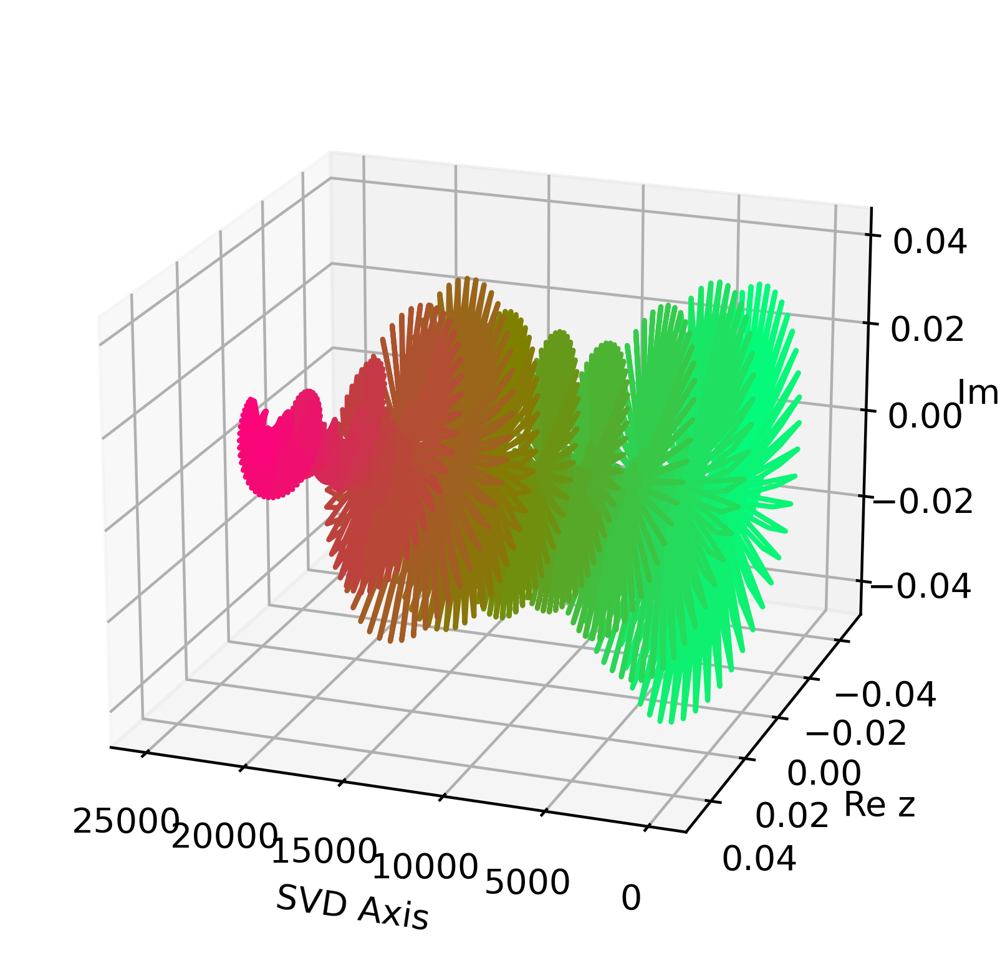

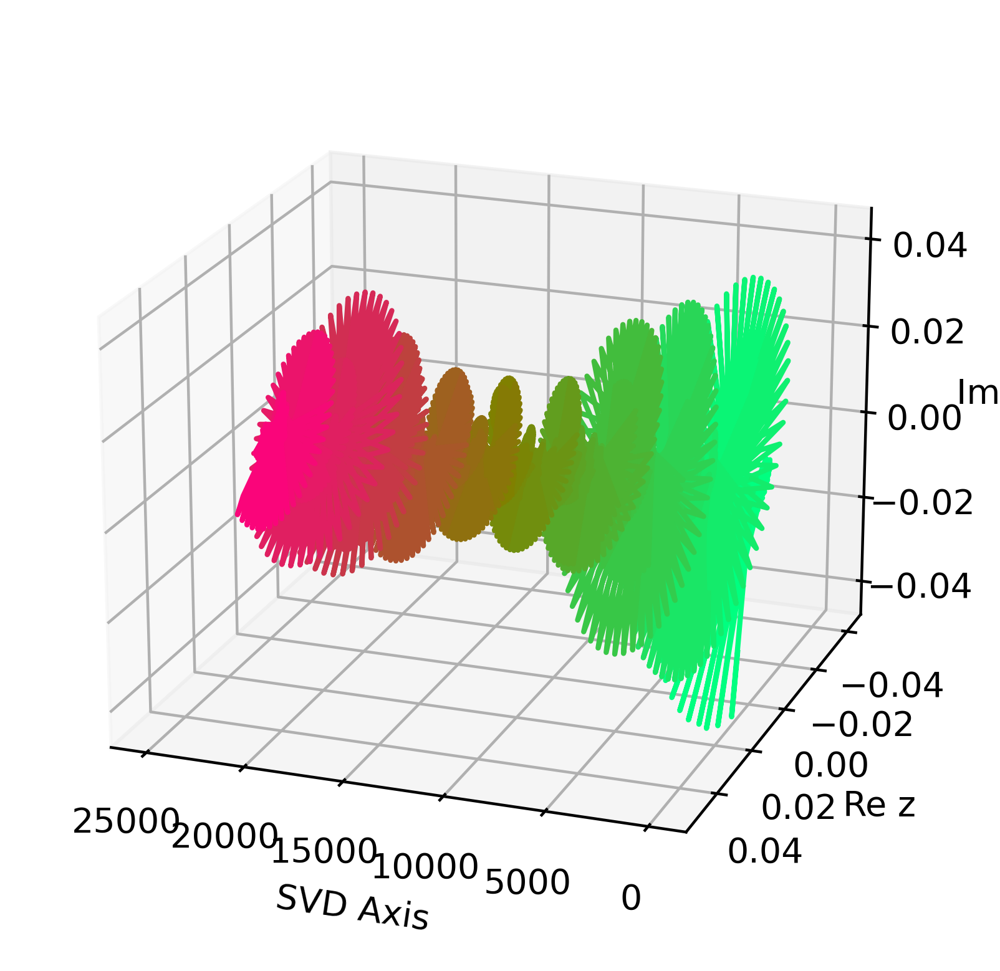

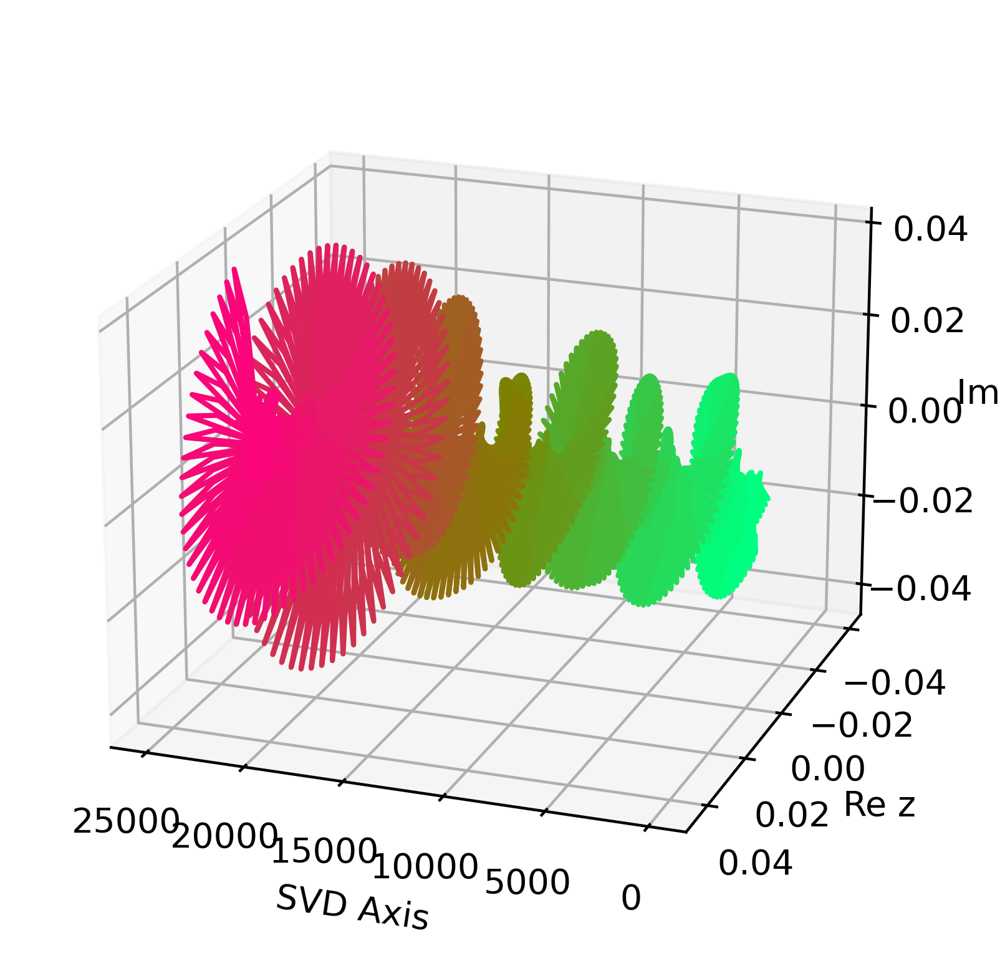

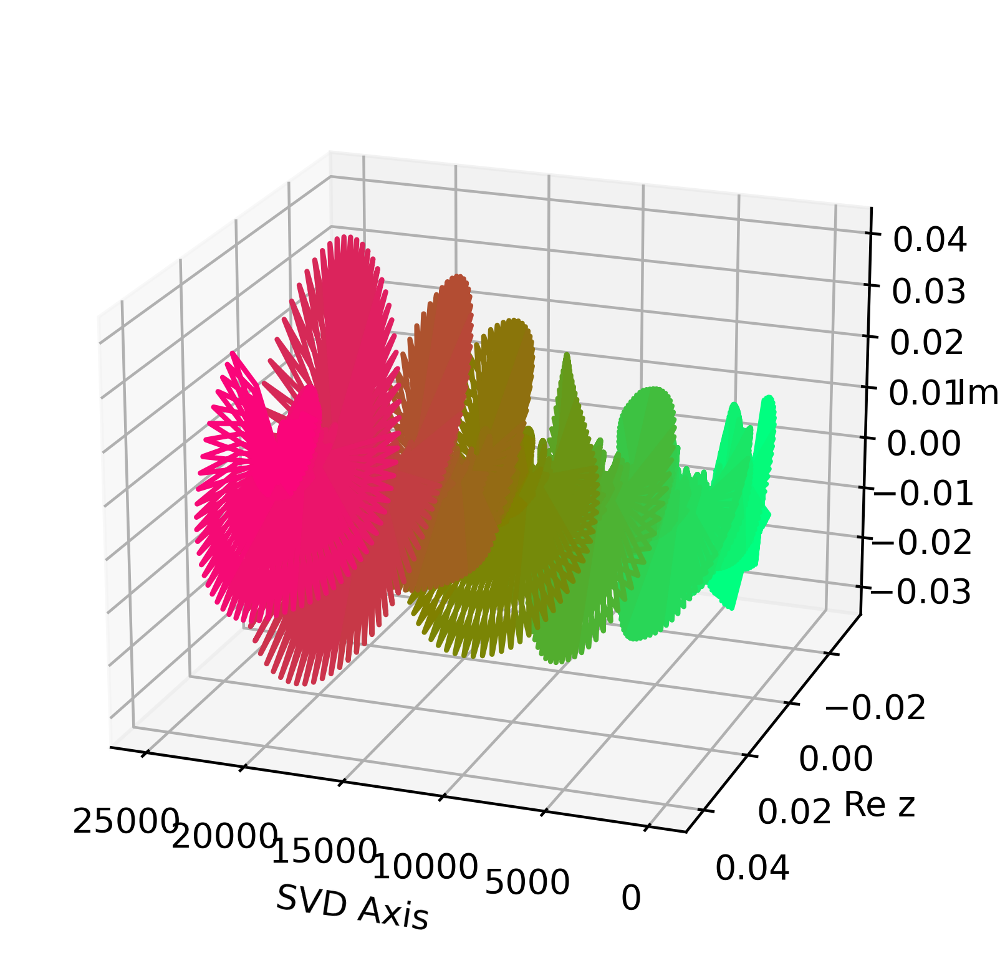

...

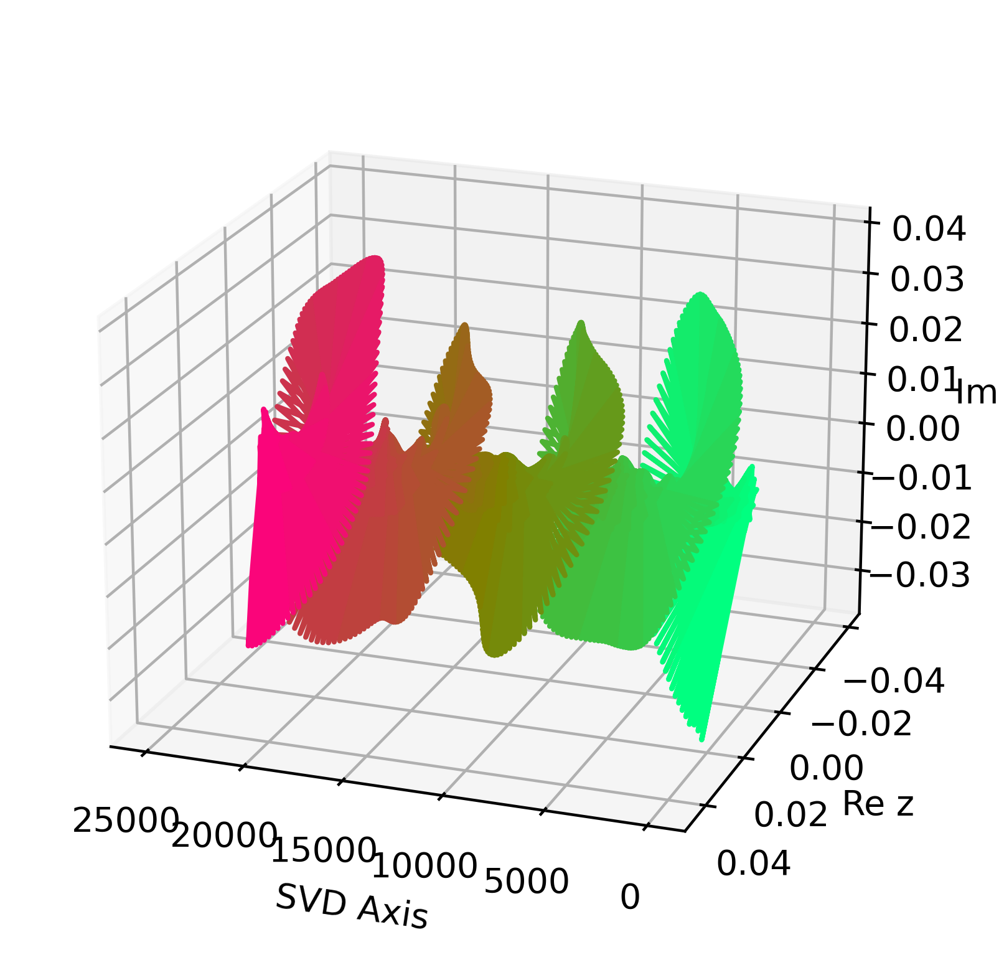

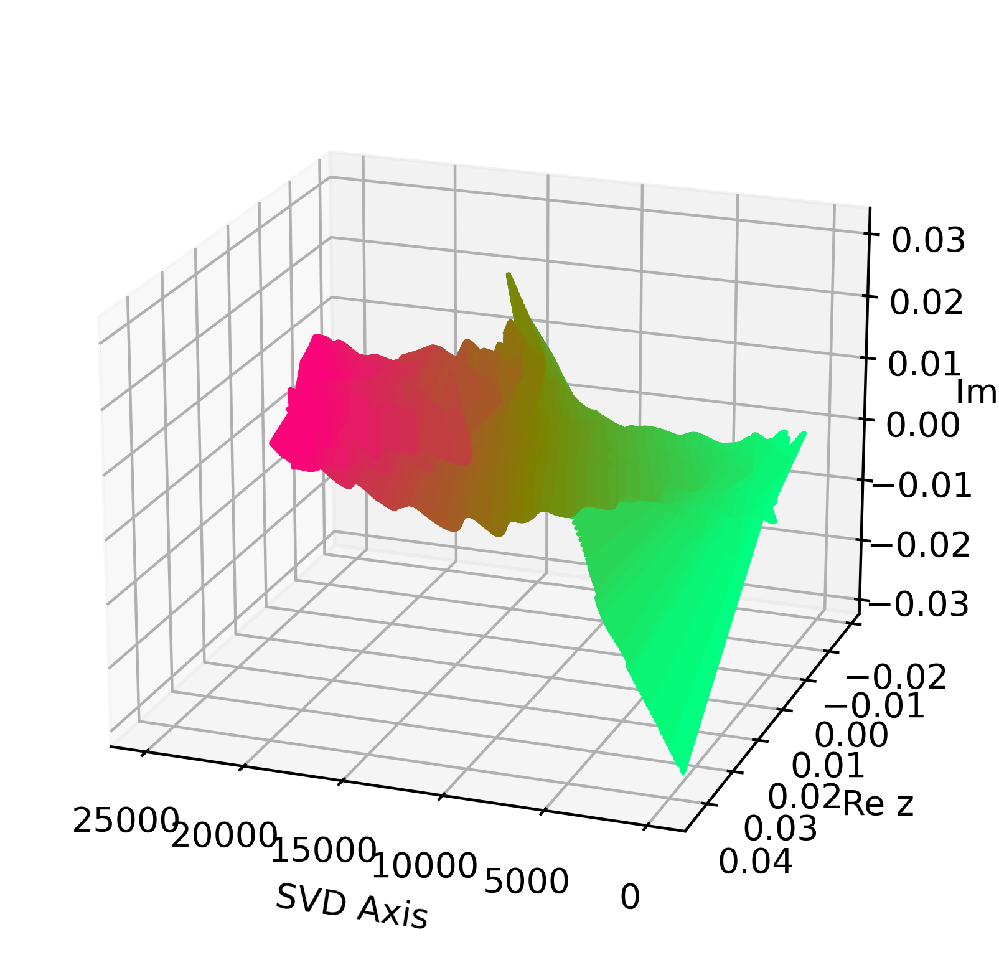

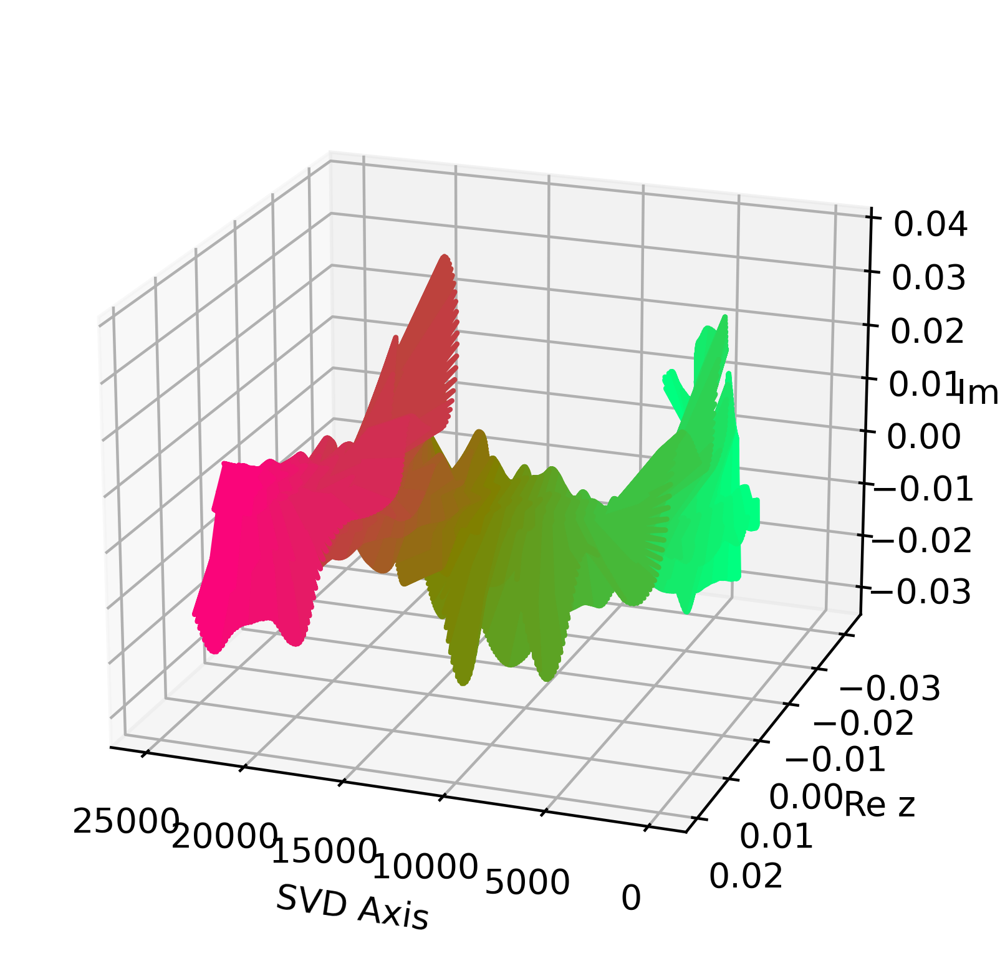

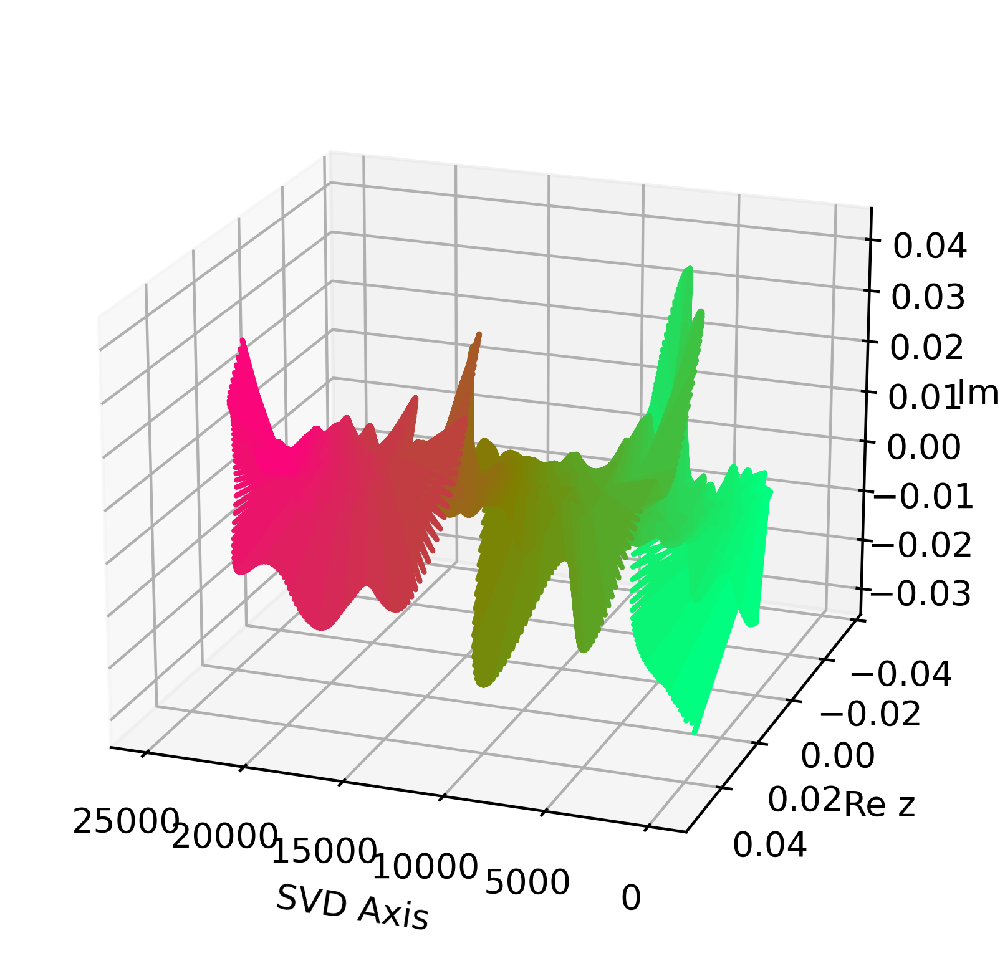

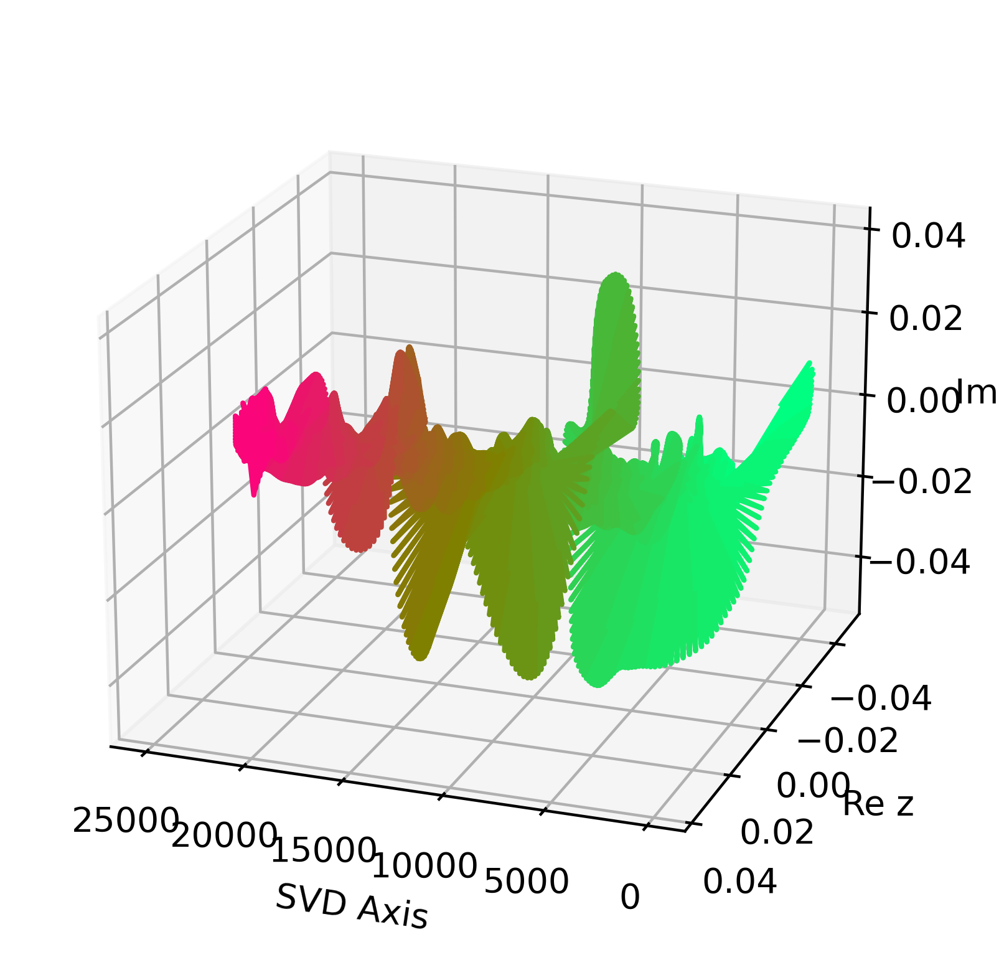

<Figure size 2560x1920 with 0 Axes>

In [80]:
n = 25000
for j in range(12):
    ax = plt.axes(projection='3d')
    for i in range(0, n, 500):
        r = i/n
        b = np.abs(n//2-i)/n
        g = (n-i)/n
        color = (r, g, b)
        ax.plot3D(np.arange(n)[i:i+501], np.real(hdmd.modes[:,2*j])[i:i+501], np.imag(hdmd.modes[:,2*j])[i:i+501],c=color)
    ax.set_xlabel("SVD Axis")
    ax.set_ylabel("Re z")b
    ax.set_zlabel("Im z")
    ax.view_init(20,110)
    plt.figure()

# Forecasting

Given the combination of stable modes and low reconstruction error, we may be able to do forecasting with HankelDMD. We will first need a few functions. The following function, taken from the HankelDMD code with a few modifications, recovers the original matrix from a pseudo Hankel matrix. I think this is done by averaging along skew diagonals, although I don't fully understand how it is done here.

In [58]:
def average_timepoints(rec,hdmd):
    space_dim = rec.shape[0] // hdmd.d
    time_instants = rec.shape[1] + hdmd.d - 1
    
    reconstructed_snapshots = np.full((time_instants, hdmd.d, space_dim), np.nan, dtype=rec.dtype)
    c_idxes = (np.array(range(hdmd.d))[:, None].repeat(2, axis=1)[None, :].repeat(rec.shape[1], axis=0))
    c_idxes[:, :, 0] += np.array(range(rec.shape[1]))[:, None]    
    
    # for each time instance, we collect all its appearences.  each
    # snapshot appears at most d times (for instance, the first appears
    # only once).
    reconstructed_snapshots[c_idxes[:, :, 0], c_idxes[:, :, 1]] = np.array(
        np.swapaxes(np.split(rec.T, hdmd.d, axis=1), 0, 1)
        )
    
    rec2 = reconstructed_snapshots
    rec2 = np.ma.array(rec2, mask=np.isnan(rec2))
    
    result = np.mean(rec2, axis=1).T
    result = result.filled(fill_value=0)
    return result

This next function computes the pseudo-Hankel matrix reconstruction given the exact DMD used by HankelDMD.

In [3]:
def dynamics(dmd,timesteps,t0,dt):
        temp = np.repeat(dmd.eigs[:, None], timesteps.shape[0], axis=1)
        tpow = (timesteps - t0) / dt
        return np.power(temp, tpow) * dmd.amplitudes[:, None]

Now we can compute a forecast.

In [79]:
hdmd = HankelDMD(24,reconstruction_method='mean',d=500,tikhonov_regularization=1e-5)
hdmd.fit(SV_normalized[:,:1000])
shift = 500
n = 1000
forecast = average_timepoints(hdmd._sub_dmd.modes@dynamics(hdmd._sub_dmd,np.arange(shift+n-hdmd.d+1),0,1))

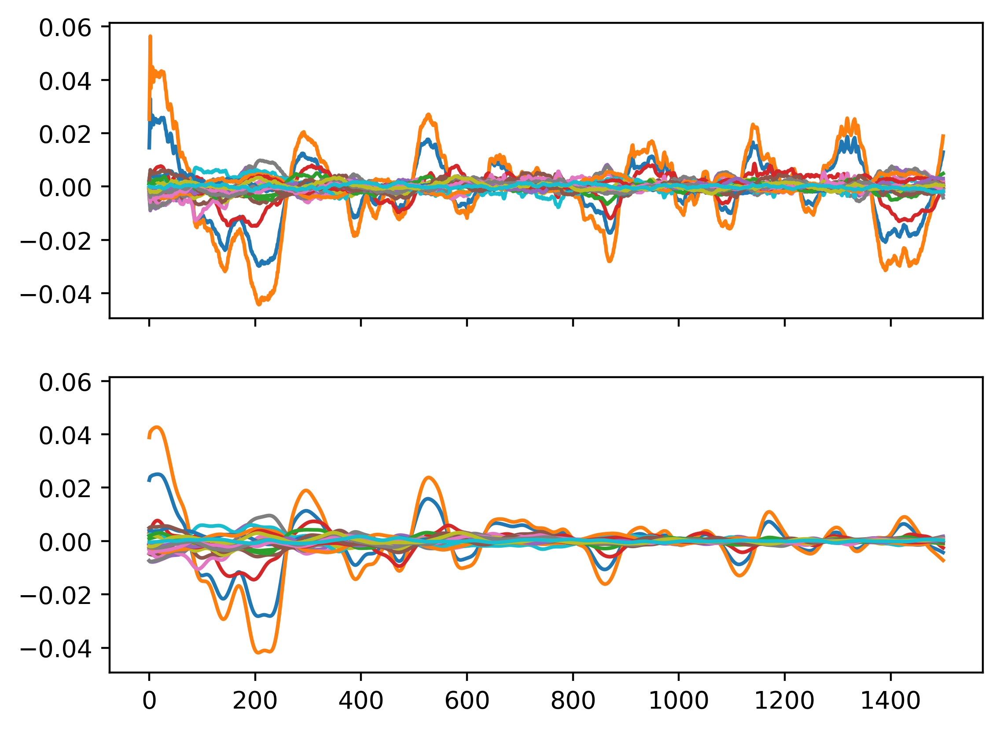

In [80]:
fig,ax = plt.subplots(2,sharex=True,sharey=True)
for i in range(20):
    ax[0].plot(SV_normalized[i,:1500])
    ax[1].plot(np.real(forecast[i]))

Let's look at the training and validation errors.

In [81]:
print("Training Error: " + str(RSE(forecast[:,:1000],SV_normalized[:,:1000])))
print("Validation Error: " + str(RSE(forecast[:,1000:],SV_normalized[:,1000:1500])))

Training Error: 0.06765393671525247
Validation Error: 1.2254626470473147


It would appear that we cannot do any forecasting, but the plot above tells a different story. Let's zoom in on the 250 timepoints after training.

Text(0.5, 0.98, 'True Data vs HankelDMD Forecast')

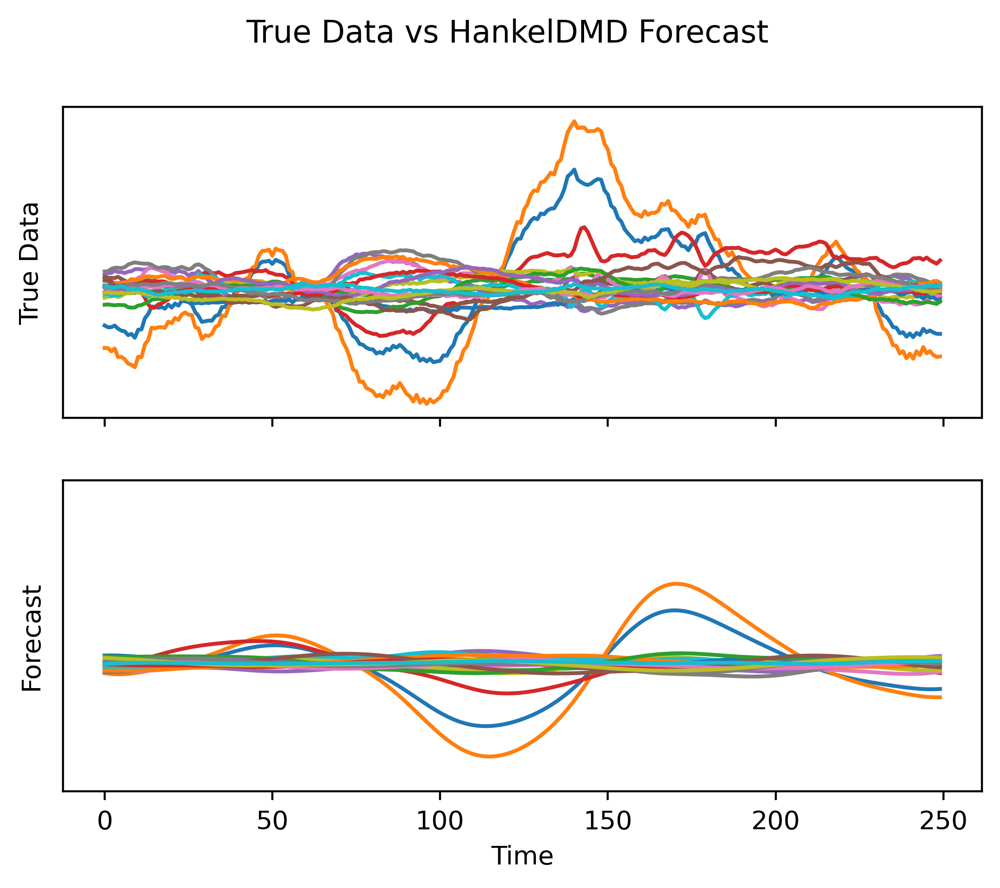

In [94]:
fig,ax = plt.subplots(2,sharex=True,sharey=True)
for i in range(20):
    ax[0].plot(SV_normalized[i,1000:1250])
    ax[1].plot(np.real(forecast[i,1000:1250]))
ax[0].set_yticks([])
ax[0].set_ylabel("True Data")
ax[1].set_ylabel("Forecast")
ax[1].set_xlabel("Time")
fig.suptitle("True Data vs HankelDMD Forecast")

This makes the issue clear: the timing of the predictions is slightly off. Let's calculate the optimal shift.

In [97]:
errors = []
for i in range(-50,100):
    errors.append(RSE(forecast[:,1000+i:1200+i],SV_normalized[:,1000:1200]))
print(np.argmin(errors)-50)
shift2 = np.argmin(errors)-50

26


So the optimal shift in this case is 26 timepoints.

Text(0.5, 0.98, 'True Data vs HankelDMD Forecast (Shifted)')

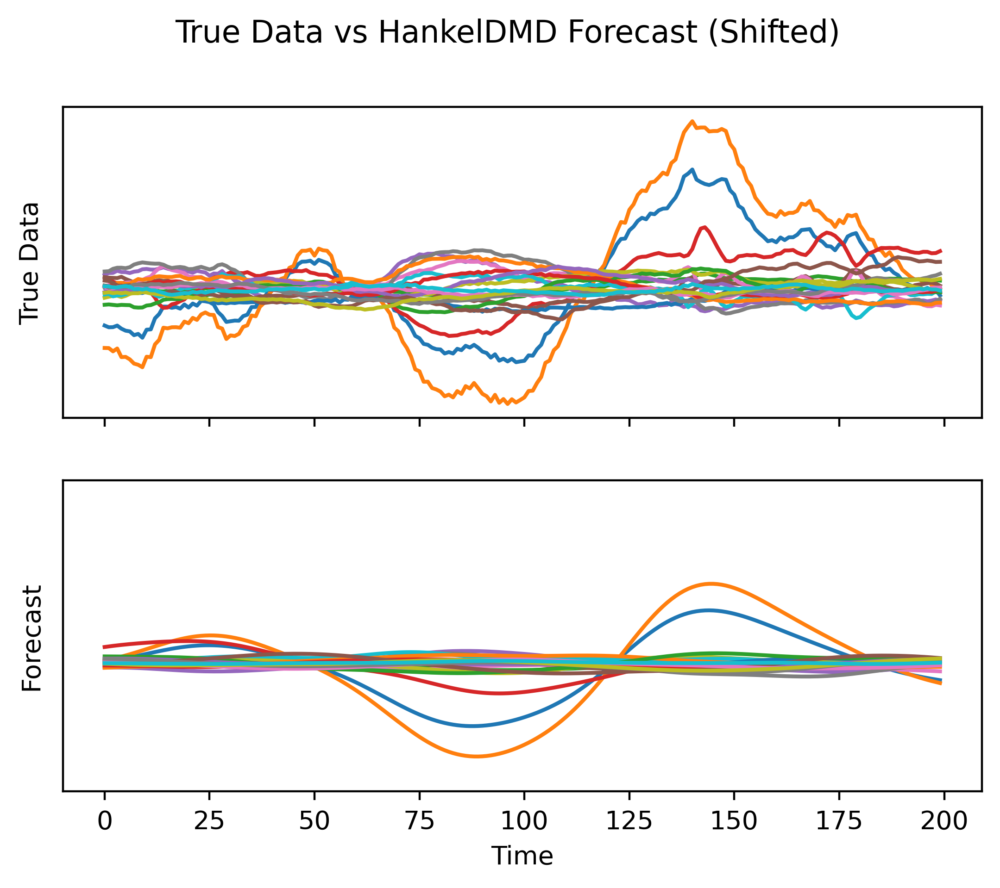

In [156]:
fig,ax = plt.subplots(2,sharex=True,sharey=True)
for i in range(20):
    ax[0].plot(SV_normalized[i,1000:1200])
    ax[1].plot(np.real(forecast[i,1000+shift2:1200+shift2]))
ax[0].set_yticks([])
ax[0].set_ylabel("True Data")
ax[1].set_ylabel("Forecast")
ax[1].set_xlabel("Time")
fig.suptitle("True Data vs HankelDMD Forecast (Shifted)")

Now we get a meaningful reconstruction. We can probably do better than this. There are many hyperparameters to explore (regularization, data length, d, HankelDMD rank), so we'll create a function to make exploring this easier.

In [59]:
def hankeldmd_compute_error(svd_rank: int, start: int, stop: int, hankel_d: int,
                            regularization: float, forecast_length: int) -> tuple:
    n = stop-start
    num_future_timepoints = 500
    
    hdmd = HankelDMD(svd_rank,reconstruction_method='mean',d=hankel_d,tikhonov_regularization=regularization)
    hdmd.fit(SV_normalized[:,start:stop])
    hankel_forecast = hdmd._sub_dmd.modes@dynamics(hdmd._sub_dmd,np.arange(n-hdmd.d+1+num_future_timepoints),0,1)
    forecast = average_timepoints(hankel_forecast,hdmd)

    train_error = RSE(forecast[:,start:stop],SV_normalized[:,start:stop])
    val_errors = []
    #val_error = RSE(forecast[:,stop:],SV_normalized[:,stop:stop+forecast_length])
    for i in range(-50,100):
        val_errors.append(RSE(forecast[:,stop+i:stop+i+forecast_length],SV_normalized[:,stop:stop+forecast_length]))
    val_error = np.min(val_errors)
    return (train_error,val_error)

Let's start by using the same window (timepoints 0-1000), d (500), regularization (none), and forecast length (200), and try numbers of modes.

In [113]:
errors = []
for i in tqdm(range(1,31)):
    errors.append(hankeldmd_compute_error(i,0,1000,500,0,200))

  0%|          | 0/30 [00:00<?, ?it/s]

Text(0.5, 1.0, 'Validation Reconstruction RSEs as Function of Number of Modes')

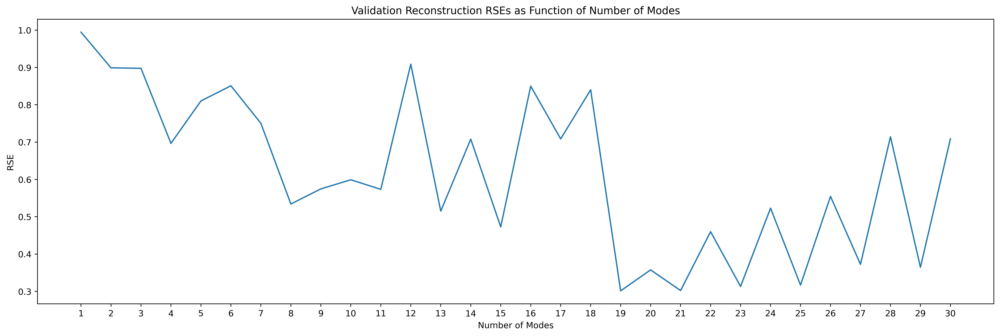

In [150]:
plt.figure(figsize=(20,6))
plt.plot(np.arange(1,31),[i[1] for i in errors])
plt.xticks(np.arange(1,31));
plt.xlabel("Number of Modes")
plt.ylabel("RSE")
plt.title("Validation Reconstruction RSEs as Function of Number of Modes")

An interesting pattern emerges here: the performance is better with an odd number of modes. This means that one of the modes will correspond to a purely real eigenvalue. The plot below shows only odd modes.

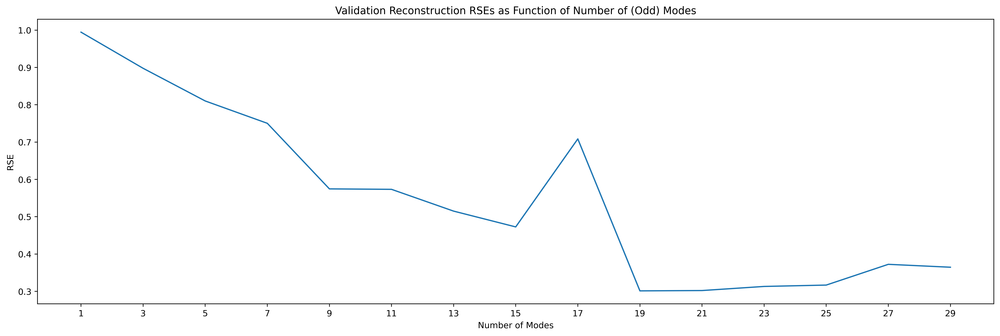

In [155]:
plt.figure(figsize=(20,6))
plt.plot(np.arange(1,31,2),[i[1] for i in errors[::2]])
plt.xticks(np.arange(1,31,2))
plt.xlabel("Number of Modes")
plt.ylabel("RSE")
plt.title("Validation Reconstruction RSEs as Function of Number of (Odd) Modes");

Let's see if we can optimize $d$ now, with the number of modes fixed at $19.$

In [60]:
errors = []
for i in tqdm(range(50,950,50)):
    errors.append(hankeldmd_compute_error(19,0,1000,i,0,200))

  0%|          | 0/18 [00:00<?, ?it/s]

/home/msw1/.local/lib/python3.11/site-packages/pydmd/snapshots.py:72: UserWarning: Input data condition number 4807075.5. Consider preprocessing data, passing in augmented data
matrix, or regularization methods.
  warnings.warn(
/home/msw1/.local/lib/python3.11/site-packages/pydmd/snapshots.py:72: UserWarning: Input data condition number 3579506.75. Consider preprocessing data, passing in augmented data
matrix, or regularization methods.
  warnings.warn(
/home/msw1/.local/lib/python3.11/site-packages/pydmd/snapshots.py:72: UserWarning: Input data condition number 2814211.75. Consider preprocessing data, passing in augmented data
matrix, or regularization methods.
  warnings.warn(
/home/msw1/.local/lib/python3.11/site-packages/pydmd/snapshots.py:72: UserWarning: Input data condition number 2186359.25. Consider preprocessing data, passing in augmented data
matrix, or regularization methods.
  warnings.warn(
/home/msw1/.local/lib/python3.11/site-packages/pydmd/snapshots.py:72: UserWarning

Text(0.5, 1.0, 'Validation Reconstruction RSEs as Function of d')

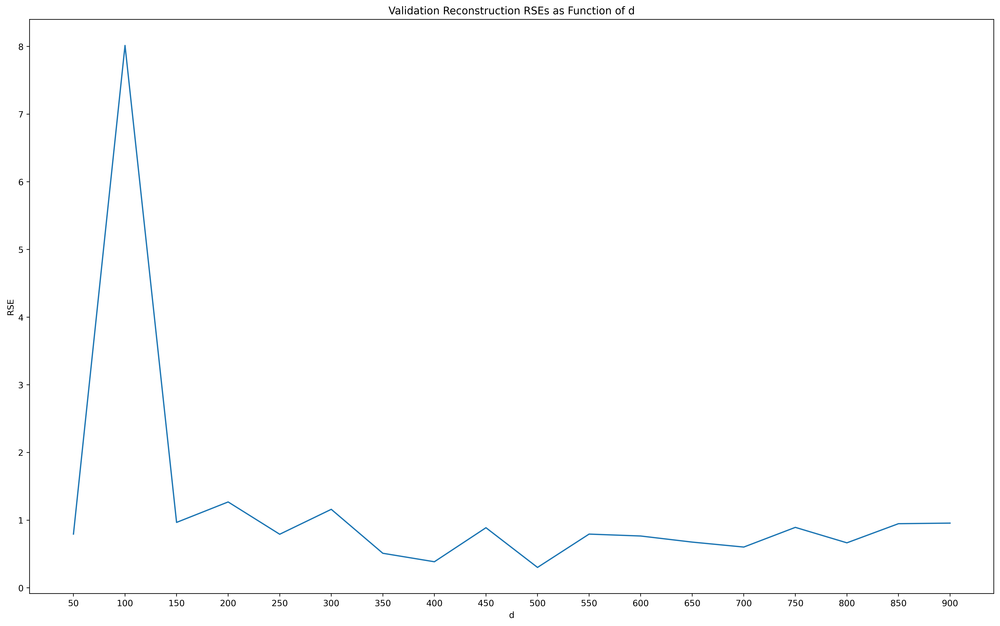

In [64]:
plt.figure(figsize=(20,12))
plt.plot(np.arange(50,950,50),[i[1] for i in errors])
plt.xticks(np.arange(50,950,50));
plt.xlabel("d")
plt.ylabel("RSE")
plt.title("Validation Reconstruction RSEs as Function of d")
#plt.ylim(0,1)

$d=500$ appears to be optimal with this set of hyperparameters.

Next let's try adding regularization to the fit.

In [71]:
errors = []
for i in tqdm(np.logspace(-16,0,17)):
    errors.append(hankeldmd_compute_error(19,0,1000,500,i,200))

  0%|          | 0/17 [00:00<?, ?it/s]

Text(0.5, 1.0, 'Validation Reconstruction RSEs as Function of Regularization Parameter')

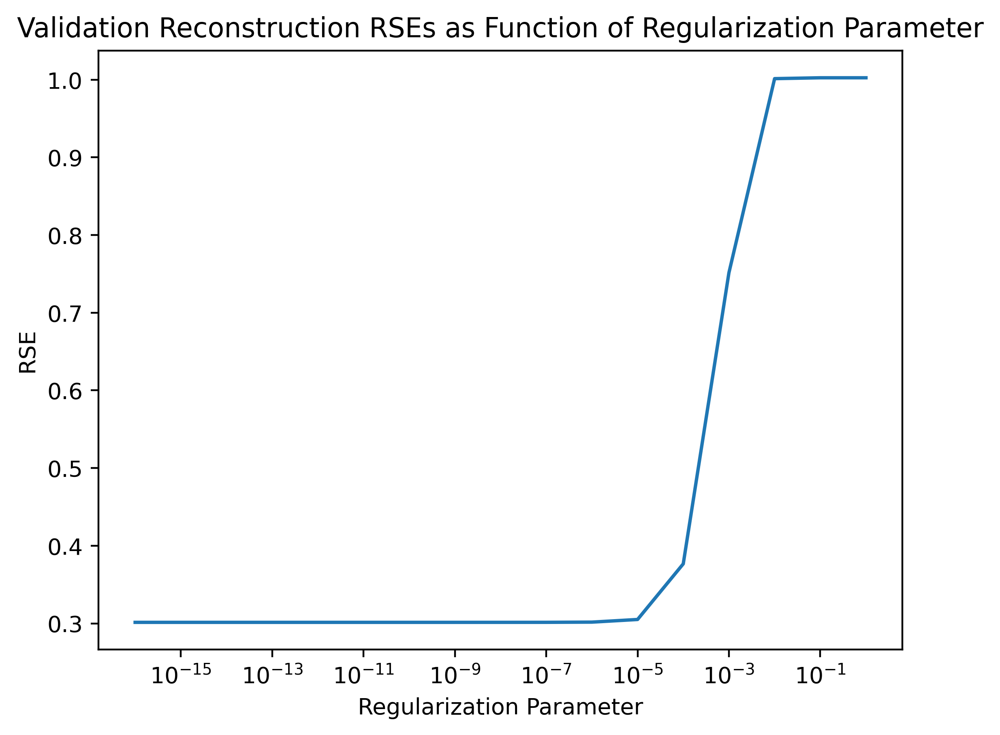

In [76]:
plt.plot(np.logspace(-16,0,17),[i[1] for i in errors])
plt.xscale('log',base=10)
plt.xlabel("Regularization Parameter")
plt.ylabel("RSE")
plt.title("Validation Reconstruction RSEs as Function of Regularization Parameter")

This form of regularization does not appear to add any benefit.

There is probably a better model out there; I have only done optimization in each parameter one at a time rather than doing a joint optimization. This could be something to work on in the future.

Let's look at the "optimal" model we have found here.

In [118]:
n = stop-start
num_future_timepoints = 500

hdmd = HankelDMD(19,reconstruction_method='mean',d=500,tikhonov_regularization=0)
hdmd.fit(SV_normalized[:,:1000])
hankel_forecast = hdmd._sub_dmd.modes@dynamics(hdmd._sub_dmd,np.arange(n-hdmd.d+1+num_future_timepoints),0,1)
forecast = average_timepoints(hankel_forecast,hdmd)
val_errors = []
#val_error = RSE(forecast[:,stop:],SV_normalized[:,stop:stop+forecast_length])
for i in range(-50,100):
    val_errors.append(RSE(forecast[:,1000+i:1000+i+200],SV_normalized[:,1000:1000+200]))
shift = np.argmin(val_errors)-50

In [120]:
RSE(forecast[:,:1000],SV_normalized[:,:1000])

0.12137027250066103

In [124]:
RSE(optdmd.reconstructed_data[:,:1000],SV_normalized[:,:1000])

0.07080805941846835

Text(0.5, 0.98, 'True Data vs Improved HankelDMD Forecast')

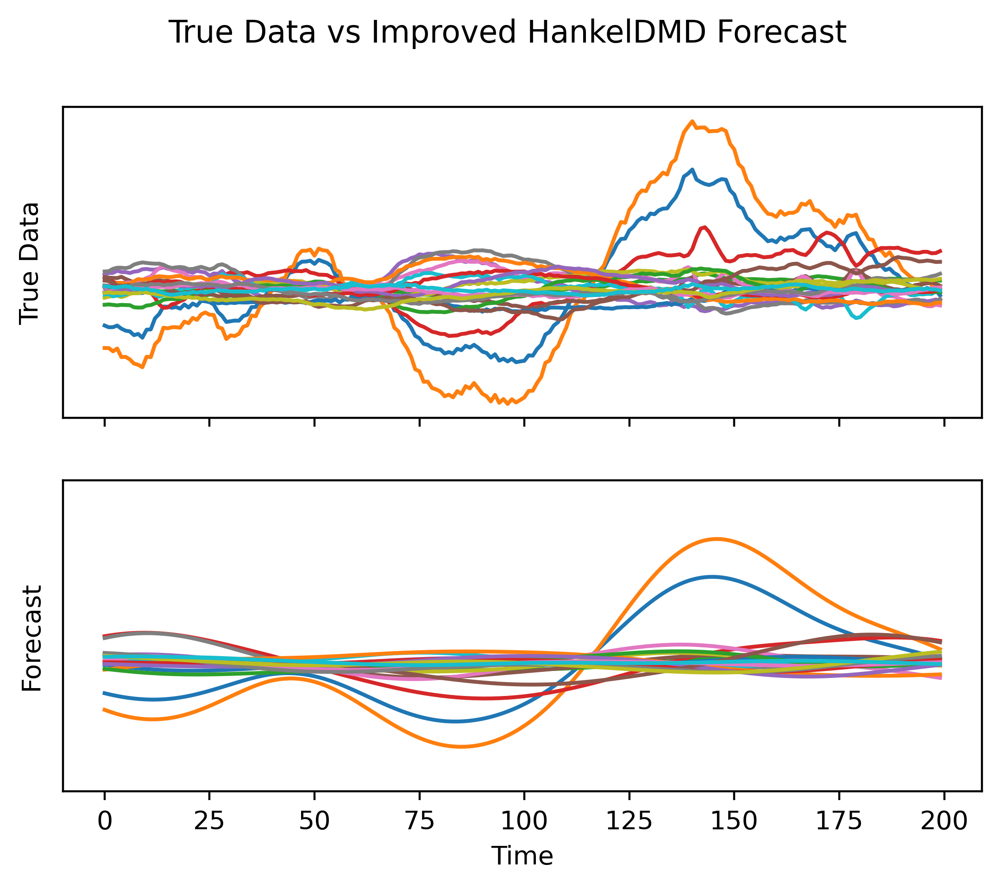

In [116]:
fig,ax = plt.subplots(2,sharex=True,sharey=True)
for i in range(20):
    ax[0].plot(SV_normalized[i,1000:1200])
    ax[1].plot(np.real(forecast[i,1000+shift:1200+shift]))
ax[0].set_yticks([])
ax[0].set_ylabel("True Data")
ax[1].set_ylabel("Forecast")
ax[1].set_xlabel("Time")
fig.suptitle("True Data vs Improved HankelDMD Forecast")

Next let's convert this into a video.

In [93]:
# Load widefield spatial data
# This data is 560x560x2000, where the first two dimensions are pixels
# and the last dimension is SVD mode. We will keep only the top 50 modes
wf_spat = np.load('../Mouse Data/svdSpatialComponents.npy')
top50 = wf_spat[:,:,:50].copy()

# Set aside memory for all matrix multiplications we will do
matmul_out = np.empty((560,560))

# Compute first frame
USV = np.matmul(top50,SV_norm*SV_normalized[:50,1000],out=matmul_out)
# Delete wf_spat from memory
del wf_spat

NameError: name 'SVn' is not defined

At iteration 0
At iteration 0
At iteration 1
At iteration 2
At iteration 3
At iteration 4
At iteration 5
At iteration 6
At iteration 7
At iteration 8
At iteration 9
At iteration 10
At iteration 11
At iteration 12
At iteration 13
At iteration 14
At iteration 15
At iteration 16
At iteration 17
At iteration 18
At iteration 19
At iteration 20
At iteration 21
At iteration 22
At iteration 23
At iteration 24
At iteration 25
At iteration 26
At iteration 27
At iteration 28
At iteration 29
At iteration 30
At iteration 31
At iteration 32
At iteration 33
At iteration 34
At iteration 35
At iteration 36
At iteration 37
At iteration 38
At iteration 39
At iteration 40
At iteration 41
At iteration 42
At iteration 43
At iteration 44
At iteration 45
At iteration 46
At iteration 47
At iteration 48
At iteration 49
At iteration 50
At iteration 51
At iteration 52
At iteration 53
At iteration 54
At iteration 55
At iteration 56
At iteration 57
At iteration 58
At iteration 59
At iteration 60
At iteration 61
At 

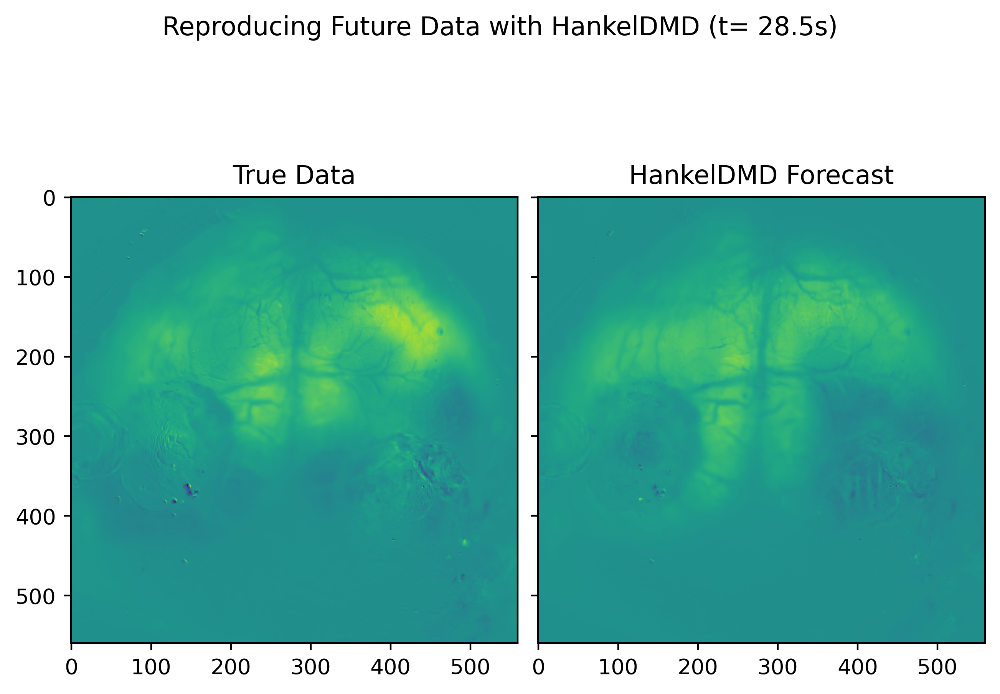

In [104]:
# Import packages for animations
import sys
import warnings
warnings.filterwarnings('ignore')
from matplotlib import animation, rc
rc('animation',html='html5')

fig,ax = plt.subplots(1,2,sharex=True,sharey=True,constrained_layout=True)
true_ax = ax[0].imshow(USV)
ax[0].set_title('True Data')
reproduce_ax = ax[1].imshow(np.matmul(top50,SV_norm*np.real(forecast[:,1000+shift]),out=matmul_out))
ax[1].set_title("HankelDMD Forecast")
im = []
dt = 0.0285
fig.suptitle("Reproducing Future Data with HankelDMD (t= " + str(1000*dt)+"s)",y=1.05)
#fig.colorbar(true_ax,ax=ax,ticks=np.arange(-2000,2000,400),format="%d")
plt.subplots_adjust(bottom=0.001, top=0.9, hspace=0)
def animate(t):
    print("At iteration " + str(t))
    # True data
    USV = np.matmul(top50,SV_norm*SV_normalized[:50,1000+t],out=matmul_out)
    true_ax.set_data(USV)
    true_ax.set_clim(-2000,2000)
    fig.suptitle("Reproducing Future Data with HankelDMD (t= " + str((1000+t)*dt)+"s)",y=1.05)
    # Reproduction
    USV = np.matmul(top50,SV_norm*np.real(forecast[:,1000+t+shift]),out=matmul_out)
    reproduce_ax.set_data(USV)
    reproduce_ax.set_clim(-2000,2000)
anim = animation.FuncAnimation(fig,animate,frames=199,save_count=None,repeat=False)
writermp4=animation.FFMpegWriter(fps=6)
anim.save('HankelDMD Forecast.mp4',writer = writermp4)

Finally let's look at the eigenvalues and modes of this fit.

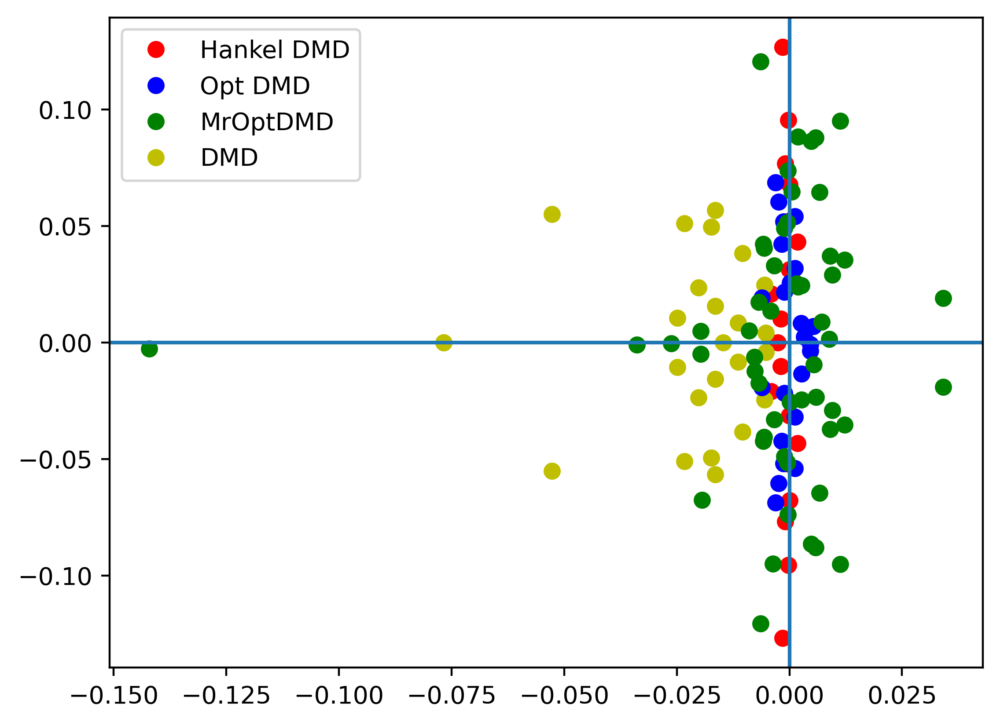

In [106]:
# Comparison of eigenvalues of Hankel DMD to eigenvalues of OptDMD/MrOptDMD
plt.plot(np.real(np.log(hdmd.eigs)[0]),np.imag(np.log(hdmd.eigs)[0]),'ro',label="Hankel DMD")
plt.plot(np.real(optdmd.eigs[0]),np.imag(optdmd.eigs[0]),'bo',label="Opt DMD")
plt.plot(np.real(mroptdmd.eigs[0]),np.imag(mroptdmd.eigs[0]),'go',label="MrOptDMD")
plt.plot(np.real(np.log(dmd.eigs)[0]),np.imag(np.log(dmd.eigs)[0]),'yo',label="DMD")
for heig in np.log(hdmd.eigs):
    plt.plot(np.real(heig),np.imag(heig),'ro')
for oeig, deig in zip(optdmd.eigs,np.log(dmd.eigs)):
    plt.plot(np.real(oeig),np.imag(oeig),'bo')
    plt.plot(np.real(deig),np.imag(deig),'yo')
for mreig in mroptdmd.eigs:
    plt.plot(np.real(mreig),np.imag(mreig),'go')
plt.axhline(0)
plt.axvline(0)
plt.legend();

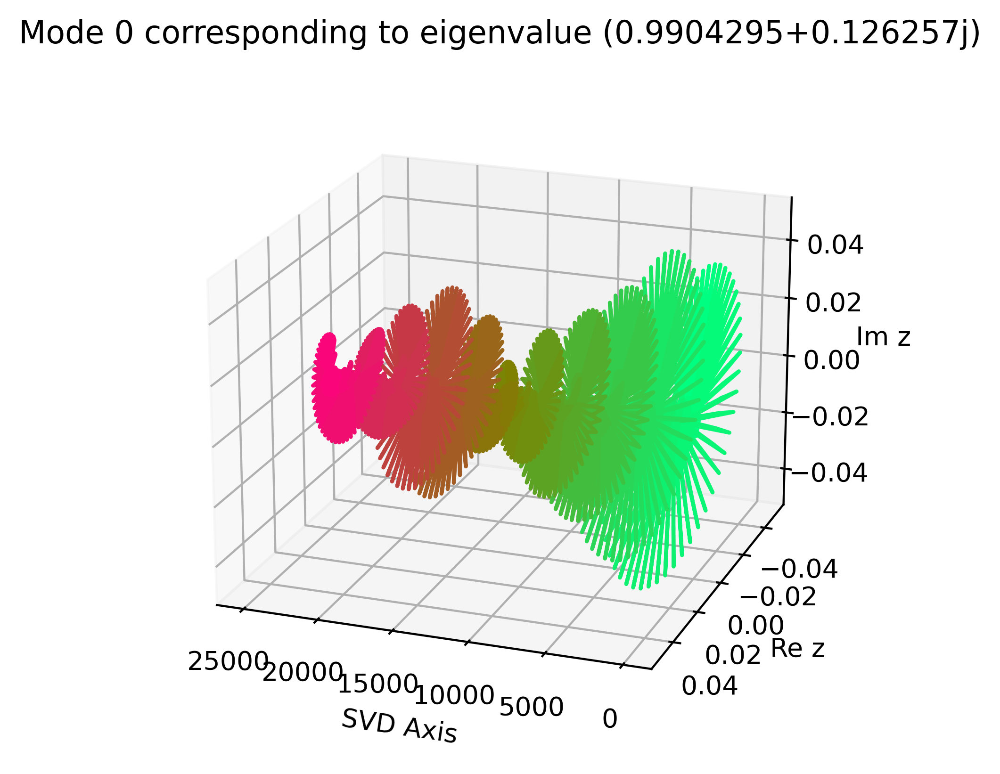

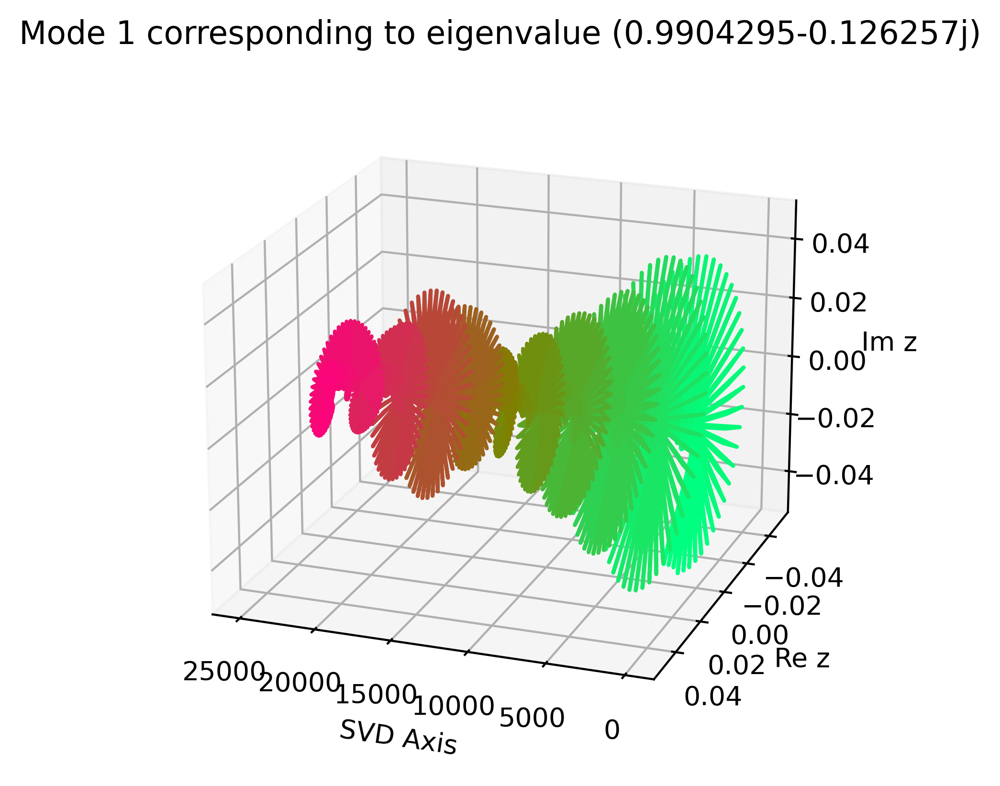

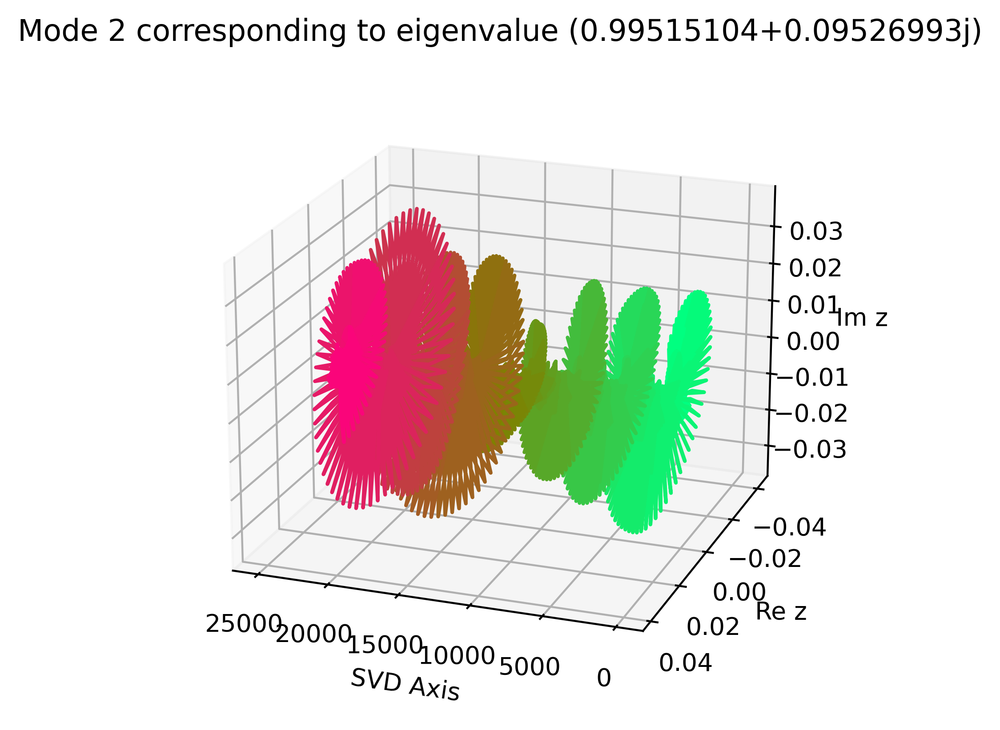

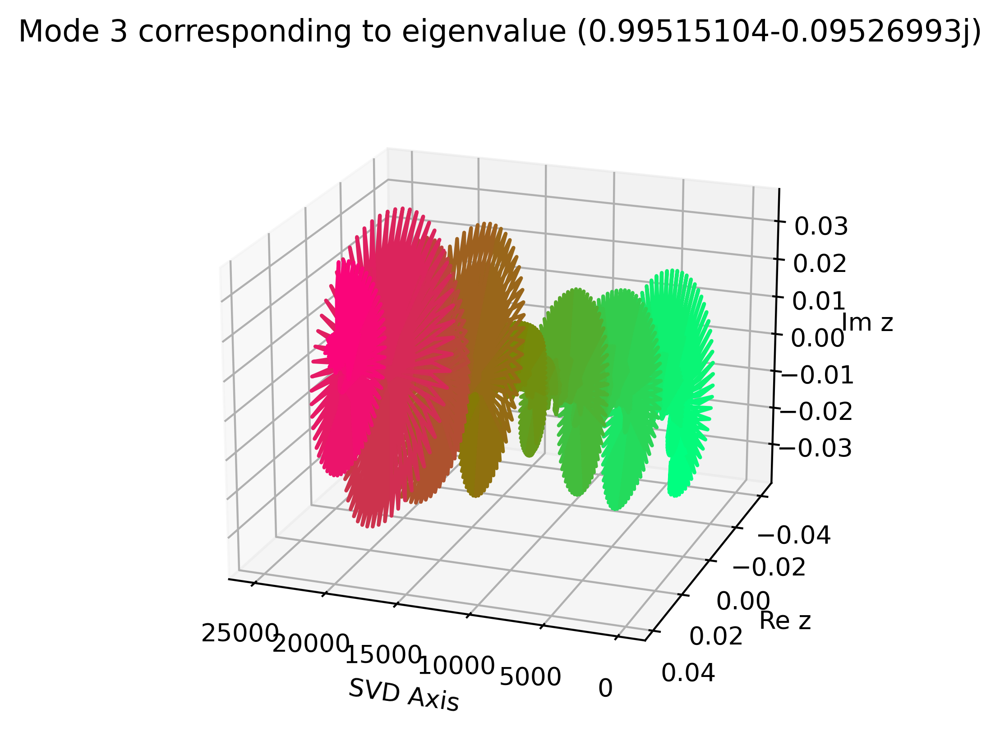

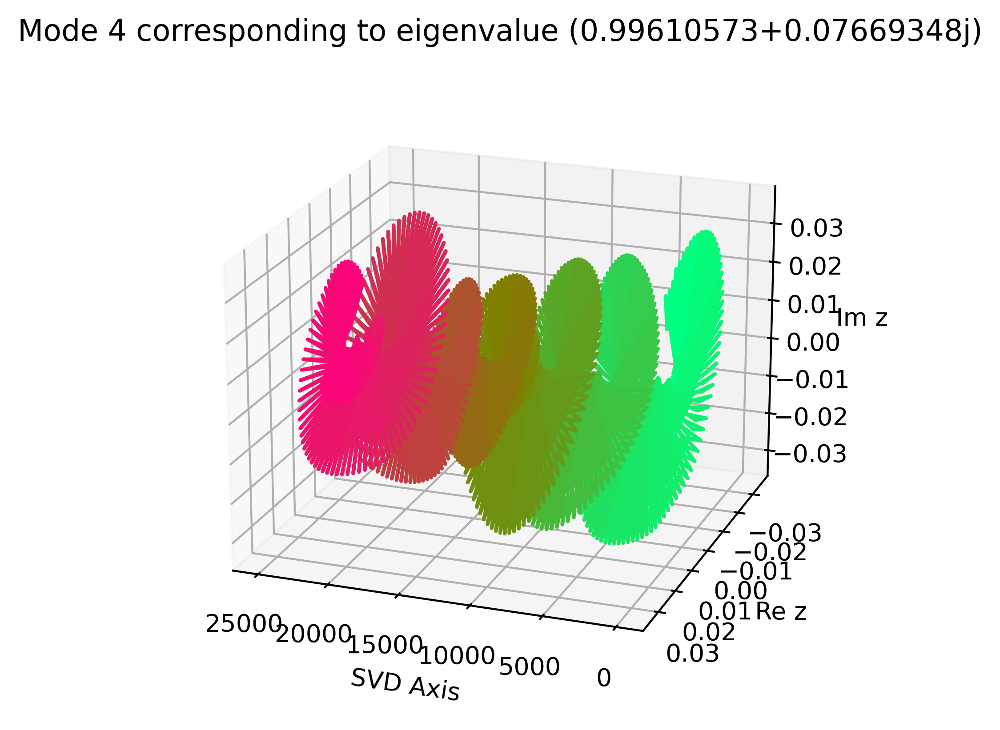

...

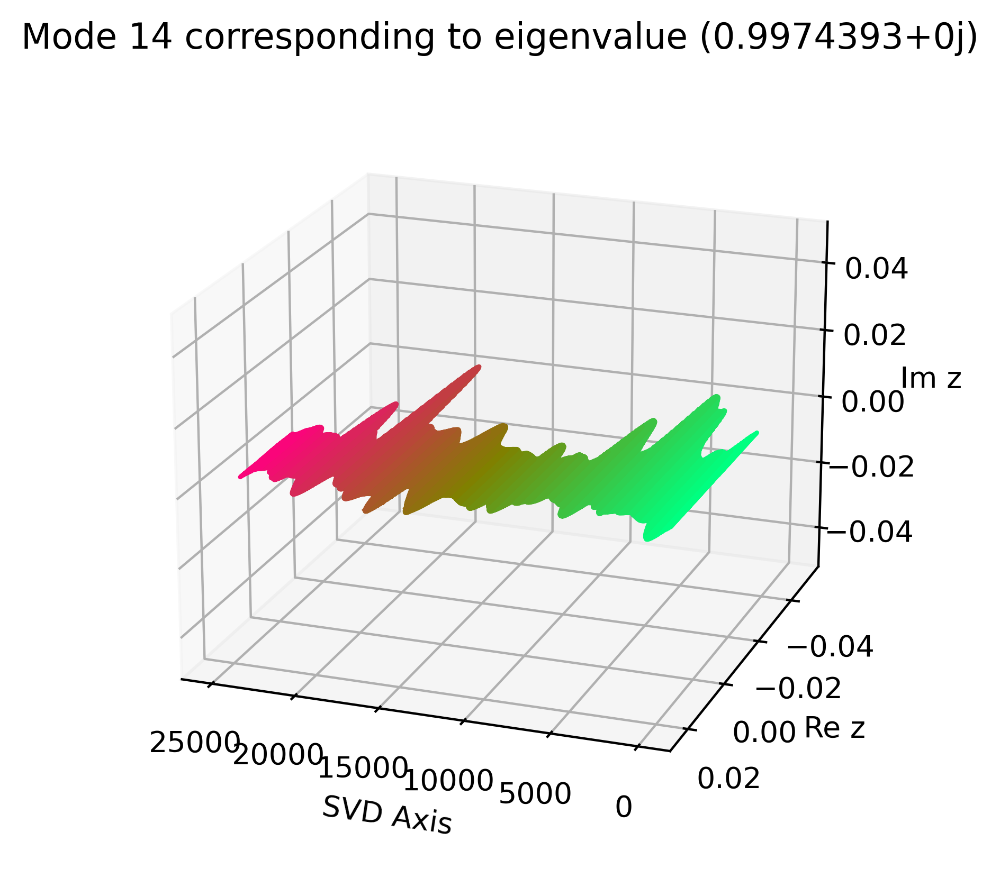

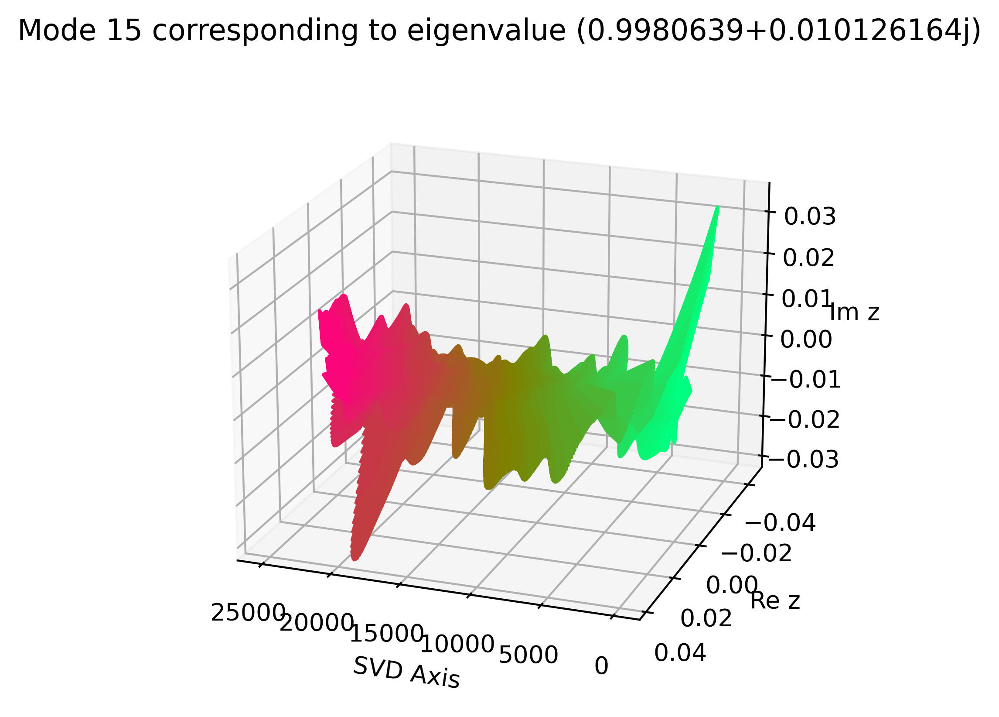

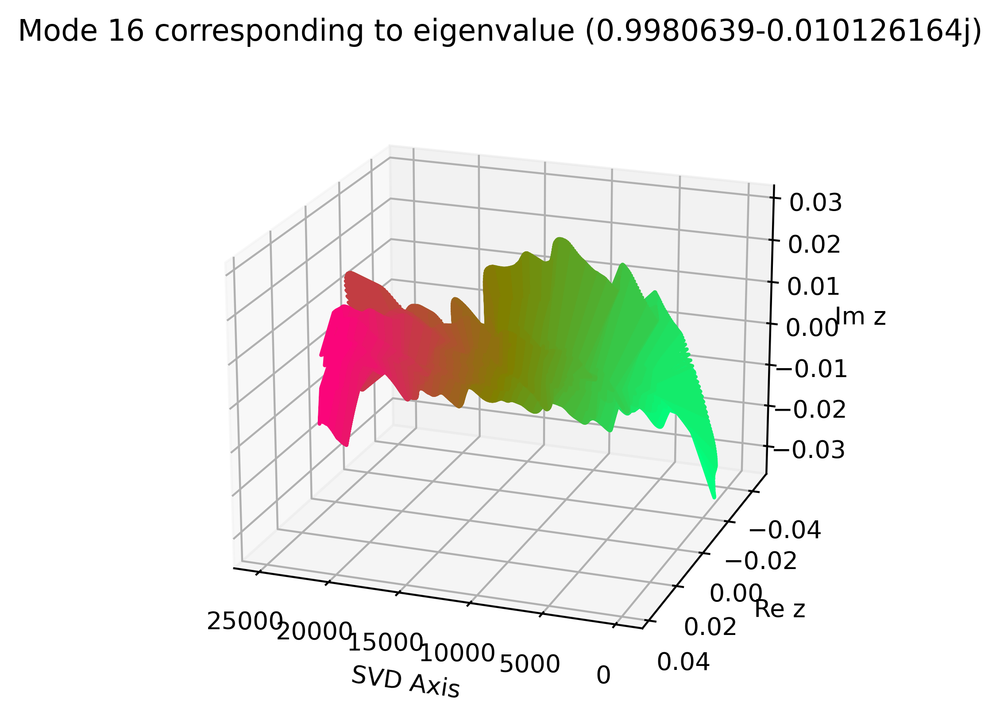

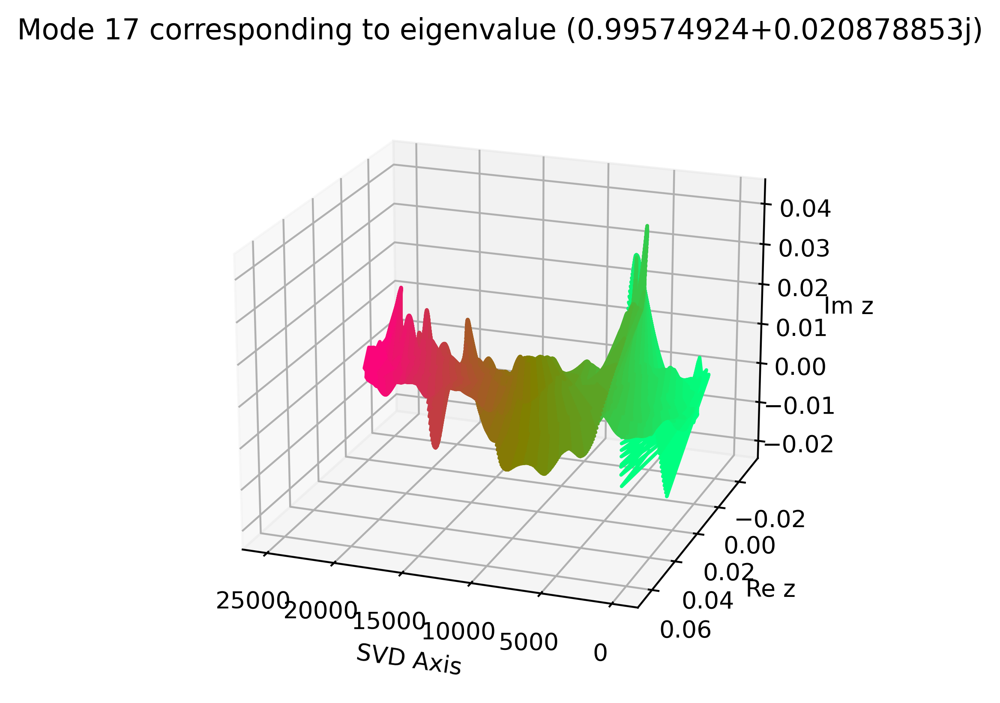

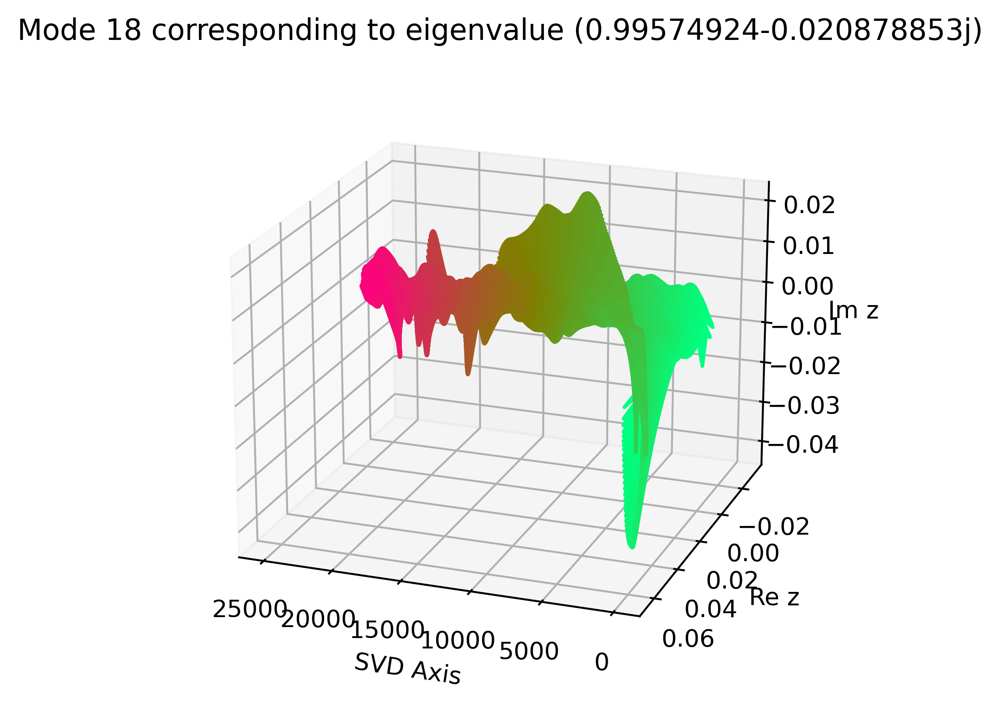

<Figure size 2560x1920 with 0 Axes>

In [114]:
n = 25000
for j in range(19):
    ax = plt.axes(projection='3d')
    for i in range(0, n, 500):
        r = i/n
        b = np.abs(n//2-i)/n
        g = (n-i)/n
        color = (r, g, b)
        ax.plot3D(np.arange(n)[i:i+501], np.real(hdmd.modes[:,j])[i:i+501], np.imag(hdmd.modes[:,j])[i:i+501],c=color)
        ax.set_title("Mode " + str(j) + " corresponding to eigenvalue " + str(hdmd.eigs[j]))
    ax.set_xlabel("SVD Axis")
    ax.set_ylabel("Re z")
    ax.set_zlabel("Im z")
    ax.view_init(20,110)
    plt.figure()